# Brain Tumor MRI Image Classification

### **Project Type** : Deep Learning / Multi-Class Image Classification

### **Domain** : Medical Imaging — Brain MRI

### **Contribution** : Individual

### **Name** : Sakshi Nawandhar

### Objective
This project develops an end-to-end deep learning pipeline to classify brain MRI images into four classes:

1. Glioma
2. Meningioma
3. No Tumor
4. Pituitary

Two deep learning approaches are developed and compared:

- **Custom CNN** trained from scratch.
- **Transfer Learning using MobileNetV2** pretrained on ImageNet.

The final selected model is saved and prepared for use in a Streamlit application.

> **Important:** This project is for educational and research purposes. Model predictions must not be treated as a medical diagnosis or as a replacement for a qualified healthcare professional.

## Submission Requirements Covered

This notebook follows the structure and expectations of the provided ML submission template:

- Well-structured and commented code.
- Clear explanation before important code sections.
- Dataset understanding and preprocessing.
- UBM-style visualization: Univariate, Bivariate and Multivariate analysis.
- At least 15 meaningful charts.
- Model explanation and evaluation metrics.
- Cross-validation / hyperparameter experimentation where practical.
- Model comparison.
- Model saving and loading.
- Unseen-image sanity check.
- Deployment-ready Streamlit code.
- Conclusion and future work.

Because this is an **image classification** problem, traditional tabular operations such as correlation matrices over business columns are not appropriate. Instead, image dimensions, class distributions, brightness, aspect ratio, augmentation, confusion matrices and class-wise performance are used.

# 1. Project Summary

### Problem Statement

Brain MRI images can belong to different diagnostic categories. Manually reviewing a large number of images is time-consuming and requires medical expertise. This project explores how deep learning can be used to automatically classify MRI images into predefined categories.

### Proposed Solution

The workflow is:

**Dataset → Data Understanding → Image Preprocessing → Data Augmentation → Custom CNN → Transfer Learning → Fine-Tuning → Evaluation → Model Comparison → Model Saving → Streamlit Deployment**

### Expected Outcome

The final system should:

- Accept an MRI image.
- Resize and preprocess the image.
- Predict one of the four dataset classes.
- Display the predicted class and confidence score.
- Provide a simple interface through Streamlit.

# 2. Dataset Structure

The dataset supplied for this project is already divided into training, validation and testing folders.

The expected project structure is:

```text
Brain_Tumor_MRI_Classification/
│
├── DATASET_DIR/
│   └── Tumour/
│       ├── train/
│       │   ├── glioma/
│       │   ├── meningioma/
│       │   ├── no_tumor/
│       │   └── pituitary/
│       │
│       ├── valid/
│       │   ├── glioma/
│       │   ├── meningioma/
│       │   ├── no_tumor/
│       │   └── pituitary/
│       │
│       └── test/
│           ├── glioma/
│           ├── meningioma/
│           ├── no_tumor/
│           └── pituitary/
│
└── brain_tumor_mri_classification.ipynb
```

The notebook therefore uses:

```python
DATASET_DIR = Path("DATASET_DIR/Tumour")
```

# 3. Import Libraries

We import only the libraries required for:

- File and path handling.
- Numerical operations.
- Data analysis.
- Image processing.
- Visualization.
- Deep learning.
- Model evaluation.
- Saving/loading the trained model.

All imports are kept in one place so that missing dependencies are easy to identify.

In [1]:
# =========================
# Import required libraries
# =========================

import os
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageStat

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

# Display the TensorFlow version so that the environment can be verified.
print("TensorFlow version:", tf.__version__)

# Display the Python version used by the notebook kernel.
import sys
print("Python version:", sys.version)

TensorFlow version: 2.21.0
Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]


# 4. Reproducibility and Project Configuration

A fixed random seed makes experiments more reproducible.

The image size is set to **224 × 224**, which is a standard input size for MobileNetV2 and many other transfer-learning architectures.

The number of epochs can be reduced if training takes too long on the local machine.

In [2]:
# =========================
# Reproducibility settings
# =========================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# =========================
# Project configuration
# =========================

# IMPORTANT:
# This path matches the folder structure shown in the VS Code Explorer.
DATASET_DIR = Path("DATASET_DIR/Tumour")

# Image dimensions expected by our deep learning models.
IMG_SIZE = (224, 224)

# Batch size controls how many images are processed together.
BATCH_SIZE = 32

# Training configuration.
INITIAL_EPOCHS = 10
FINE_TUNE_EPOCHS = 5

# Output folders.
OUTPUT_DIR = Path("outputs")
MODEL_DIR = OUTPUT_DIR / "models"
PLOT_DIR = OUTPUT_DIR / "plots"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset path:", DATASET_DIR.resolve())
print("Dataset exists:", DATASET_DIR.exists())
print("Output folder:", OUTPUT_DIR.resolve())

Dataset path: C:\Users\Dell\Downloads\Brain_Tumor_MRI_Classification\Brain_Tumor_MRI_Classification\DATASET_DIR\Tumour
Dataset exists: False
Output folder: C:\Users\Dell\Downloads\Brain_Tumor_MRI_Classification\Brain_Tumor_MRI_Classification\outputs


# 5. Validate Dataset Folders

Before loading thousands of images, we first verify that the required folders exist.

This is an important production-style practice because it gives a clear error message instead of allowing the notebook to fail later with a confusing `FileNotFoundError`.

In [3]:
# ==========================================
# Check the actual notebook working directory
# and the folders available there
# ==========================================

from pathlib import Path

# Show where Python is currently working
current_folder = Path.cwd()

print("CURRENT WORKING DIRECTORY:")
print(current_folder.resolve())

print("\nFOLDERS AND FILES AVAILABLE HERE:")
for item in current_folder.iterdir():
    print(" -", item.name)

print("\nPARENT FOLDER:")
print(current_folder.parent.resolve())

print("\nFOLDERS AND FILES IN PARENT:")
for item in current_folder.parent.iterdir():
    print(" -", item.name)

CURRENT WORKING DIRECTORY:
C:\Users\Dell\Downloads\Brain_Tumor_MRI_Classification\Brain_Tumor_MRI_Classification

FOLDERS AND FILES AVAILABLE HERE:
 - app.py
 - Brain_Tumor_MRI_Image_Classification.ipynb
 - dataset (2)
 - outputs

PARENT FOLDER:
C:\Users\Dell\Downloads\Brain_Tumor_MRI_Classification

FOLDERS AND FILES IN PARENT:
 - Brain_Tumor_MRI_Classification


In [4]:
# ==========================================
# Validate the expected dataset folder layout
# ==========================================

from pathlib import Path

# The dataset folder is inside the same folder
# where this notebook is running.
#
# Structure:
# dataset (2)
#     └── Tumour
#           ├── train
#           ├── valid
#           └── test

DATASET_DIR = Path("dataset (2)/Tumour")

# Dataset splits that we expect
required_splits = ["train", "valid", "test"]


# ------------------------------------------
# Step 1: Check whether the Tumour folder
# exists
# ------------------------------------------

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder was not found at: {DATASET_DIR.resolve()}\n"
        "Please check the DATASET_DIR path."
    )


# ------------------------------------------
# Step 2: Check train, valid and test folders
# ------------------------------------------

missing_splits = [
    split
    for split in required_splits
    if not (DATASET_DIR / split).exists()
]


# ------------------------------------------
# Step 3: Stop if any split is missing
# ------------------------------------------

if missing_splits:
    raise FileNotFoundError(
        f"Missing dataset split folder(s): {missing_splits}\n"
        f"Expected them inside: {DATASET_DIR.resolve()}"
    )


# ------------------------------------------
# Step 4: Display validation result
# ------------------------------------------

print("Dataset folder validation successful.")

for split in required_splits:
    print(f"✓ {split}: {(DATASET_DIR / split).resolve()}")

Dataset folder validation successful.
✓ train: C:\Users\Dell\Downloads\Brain_Tumor_MRI_Classification\Brain_Tumor_MRI_Classification\dataset (2)\Tumour\train
✓ valid: C:\Users\Dell\Downloads\Brain_Tumor_MRI_Classification\Brain_Tumor_MRI_Classification\dataset (2)\Tumour\valid
✓ test: C:\Users\Dell\Downloads\Brain_Tumor_MRI_Classification\Brain_Tumor_MRI_Classification\dataset (2)\Tumour\test


# 6. Detect Class Names

The class names are read directly from the training-folder subdirectories.

This is safer than manually typing class names because the model will use exactly the same class ordering throughout training, evaluation and Streamlit deployment.

In [5]:
# =====================================
# Detect class names automatically
# =====================================

train_dir = DATASET_DIR / "train"

class_names = sorted([
    folder.name
    for folder in train_dir.iterdir()
    if folder.is_dir()
])

if len(class_names) < 2:
    raise ValueError(
        "At least two class folders are required for classification."
    )

print("Detected classes:")
for index, class_name in enumerate(class_names):
    print(f"{index}: {class_name}")

print("\nNumber of classes:", len(class_names))

Detected classes:
0: glioma
1: meningioma
2: no_tumor
3: pituitary

Number of classes: 4


# 7. Create an Image Metadata DataFrame

For EDA, we create a DataFrame containing:

- Dataset split.
- Image path.
- Class name.
- File extension.
- Image width.
- Image height.
- Aspect ratio.
- Approximate brightness.

This does not modify the original images. It only creates metadata for analysis.

In [6]:
# ==========================================
# Build image metadata for EDA
# ==========================================

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def collect_image_metadata(split_name):
    """Collect metadata for every valid image in one dataset split."""

    split_dir = DATASET_DIR / split_name
    records = []

    for class_name in class_names:
        class_dir = split_dir / class_name

        if not class_dir.exists():
            print(f"Warning: missing class folder: {class_dir}")
            continue

        for image_path in class_dir.rglob("*"):
            if image_path.suffix.lower() not in VALID_EXTENSIONS:
                continue

            try:
                with Image.open(image_path) as img:
                    width, height = img.size
                    grayscale = img.convert("L")
                    brightness = float(ImageStat.Stat(grayscale).mean[0])

                records.append({
                    "split": split_name,
                    "class": class_name,
                    "path": str(image_path),
                    "extension": image_path.suffix.lower(),
                    "width": width,
                    "height": height,
                    "aspect_ratio": width / height if height else np.nan,
                    "brightness": brightness
                })

            except Exception as exc:
                print(f"Could not read {image_path}: {exc}")

    return pd.DataFrame(records)

# Collect metadata for all three splits.
train_meta = collect_image_metadata("train")
valid_meta = collect_image_metadata("valid")
test_meta = collect_image_metadata("test")

image_df = pd.concat(
    [train_meta, valid_meta, test_meta],
    ignore_index=True
)

print("Total valid images:", len(image_df))
display(image_df.head())

Total valid images: 2443


,split,class,path,extension,width,height,aspect_ratio,brightness
0,train,glioma,dataset (2)\Tumour\train\glioma\Tr-gl_0011_jpg...,.jpg,640,640,1.0,33.068184
1,train,glioma,dataset (2)\Tumour\train\glioma\Tr-gl_0013_jpg...,.jpg,640,640,1.0,32.319788
2,train,glioma,dataset (2)\Tumour\train\glioma\Tr-gl_0014_jpg...,.jpg,640,640,1.0,37.798232
3,train,glioma,dataset (2)\Tumour\train\glioma\Tr-gl_0015_jpg...,.jpg,640,640,1.0,37.323381
4,train,glioma,dataset (2)\Tumour\train\glioma\Tr-gl_0016_jpg...,.jpg,640,640,1.0,33.590249


# 8. Dataset Rows and Basic Information

This section checks the number of image records and the metadata data types.

For an image dataset, the DataFrame is not the model input itself. It is mainly an analysis table that helps us understand the dataset before training.

In [7]:
# =====================================
# Basic dataset inspection
# =====================================

print("Shape of image metadata:", image_df.shape)

print("\nDataset information:")
image_df.info()

print("\nMissing values:")
display(image_df.isna().sum().to_frame("missing_values"))

print("\nDuplicate image paths:")
print(image_df["path"].duplicated().sum())

Shape of image metadata: (2443, 8)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443 entries, 0 to 2442
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   split         2443 non-null   object 
 1   class         2443 non-null   object 
 2   path          2443 non-null   object 
 3   extension     2443 non-null   object 
 4   width         2443 non-null   int64  
 5   height        2443 non-null   int64  
 6   aspect_ratio  2443 non-null   float64
 7   brightness    2443 non-null   float64
dtypes: float64(2), int64(2), object(4)
memory usage: 152.8+ KB

Missing values:


,missing_values
split,0
class,0
path,0
extension,0
width,0
height,0
aspect_ratio,0
brightness,0



Duplicate image paths:
0


# 9. Exploratory Data Analysis — UBM Approach

The provided submission template asks for meaningful visualization using:

- **U — Univariate Analysis**
- **B — Bivariate Analysis**
- **M — Multivariate Analysis**

For image classification, the most useful visual questions are:

- How many images are available in each class?
- Is the dataset balanced?
- How do image dimensions vary?
- What are typical aspect ratios?
- Are some classes brighter/darker?
- Are there duplicate files?
- What do representative MRI images look like?
- How does augmentation change the images?
- Which classes are confused by the models?

We will create more than 15 meaningful charts throughout the notebook.

## Chart 1 — Overall Class Distribution

**Why this chart?**  
A count plot is suitable for comparing the number of images across categorical classes.

**What insight does it provide?**  
It reveals whether the dataset is balanced or whether some tumor categories have substantially more images.

**Potential impact:**  
Class imbalance can cause a model to perform well on common classes but poorly on minority classes. If imbalance exists, we use class weights during training.

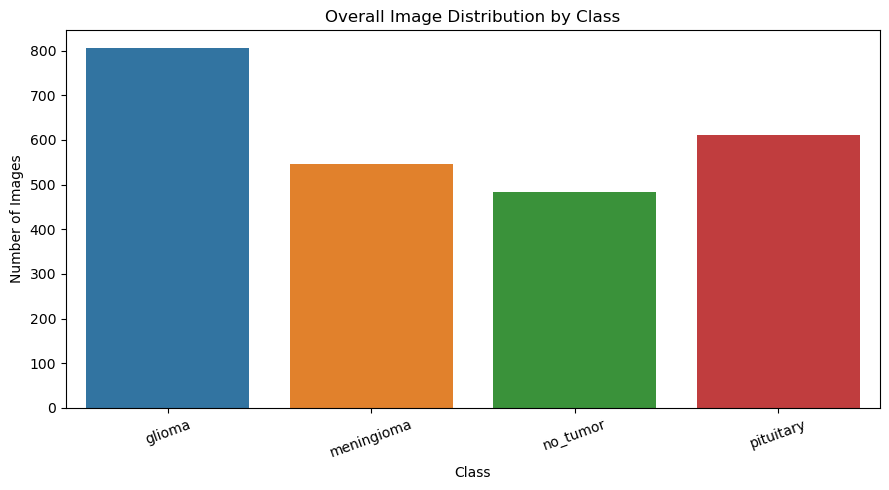

Class counts:


,image_count
class,
glioma,805
meningioma,545
no_tumor,483
pituitary,610


Insight: The largest class contains 805 images, while the smallest class contains 483 images.


In [8]:
# ==========================================
# Chart 1: Overall class distribution
# ==========================================

plt.figure(figsize=(9, 5))
sns.countplot(
    data=image_df,
    x="class",
    hue="class",
    order=class_names,
    legend=False
)
plt.title("Overall Image Distribution by Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

class_counts = image_df["class"].value_counts().reindex(class_names)
print("Class counts:")
display(class_counts.to_frame("image_count"))

print(
    f"Insight: The largest class contains {class_counts.max():,} images, "
    f"while the smallest class contains {class_counts.min():,} images."
)

## Chart 2 — Train / Validation / Test Distribution

**Why this chart?**  
A grouped count plot verifies whether all dataset splits contain the expected classes.

**Insight:**  
A class should normally be represented in train, validation and test sets. This helps us evaluate the model fairly.

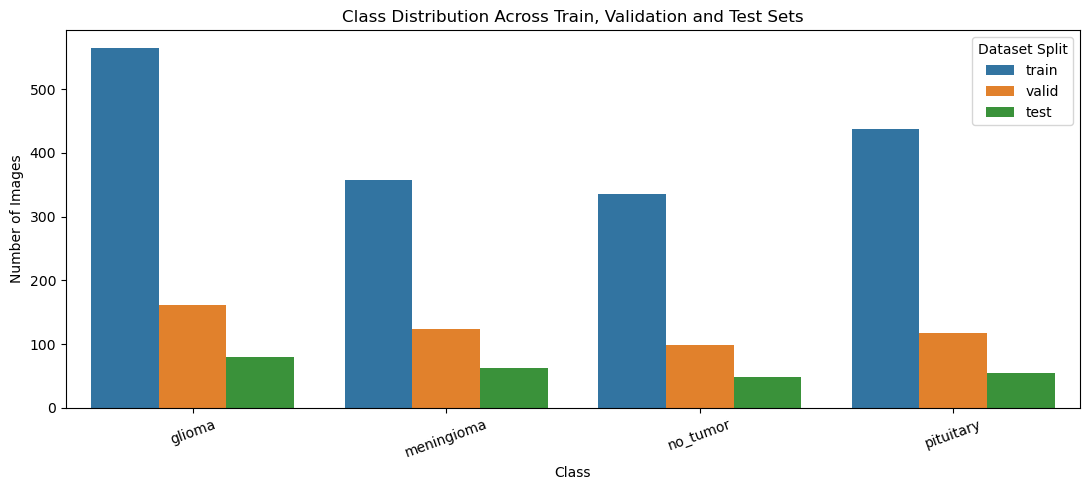

split,test,train,valid
class,,,
glioma,80,564,161
meningioma,63,358,124
no_tumor,49,335,99
pituitary,54,438,118


In [9]:
# ==========================================
# Chart 2: Split-wise class distribution
# ==========================================

plt.figure(figsize=(11, 5))
sns.countplot(
    data=image_df,
    x="class",
    hue="split",
    order=class_names
)
plt.title("Class Distribution Across Train, Validation and Test Sets")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()

split_table = pd.crosstab(image_df["class"], image_df["split"])
display(split_table)

## Chart 3 — Percentage Contribution of Each Class

**Why this chart?**  
A percentage bar chart makes class imbalance easier to interpret independent of total dataset size.

**Insight:**  
Classes with very different percentages may require class weighting or additional augmentation.

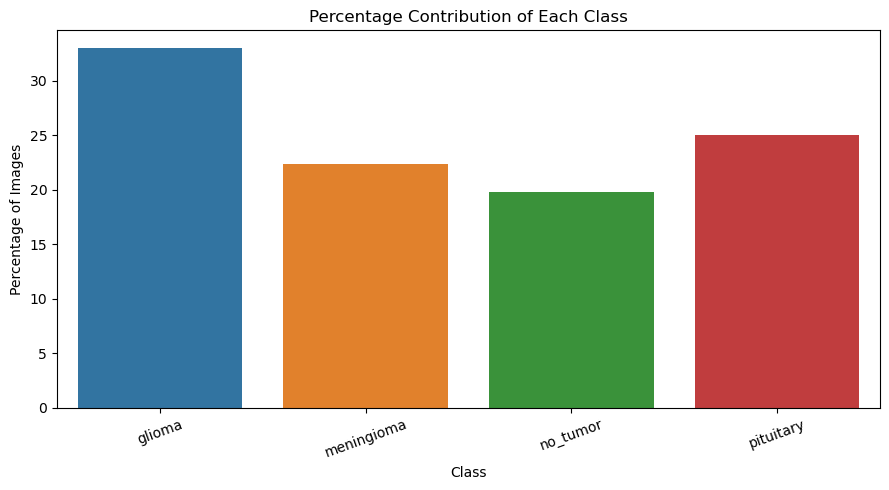

Class percentage:


,percentage
class,
glioma,32.95
meningioma,22.31
no_tumor,19.77
pituitary,24.97


In [10]:
# ==========================================
# Chart 3: Class percentage distribution
# ==========================================

class_percentage = (
    image_df["class"]
    .value_counts(normalize=True)
    .reindex(class_names)
    .mul(100)
)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=class_percentage.index,
    y=class_percentage.values,
    hue=class_percentage.index,
    legend=False
)
plt.title("Percentage Contribution of Each Class")
plt.xlabel("Class")
plt.ylabel("Percentage of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

print("Class percentage:")
display(class_percentage.round(2).to_frame("percentage"))

## Chart 4 — Image Width Distribution

**Why this chart?**  
MRI images may have different original widths. Understanding this variation justifies resizing before model training.

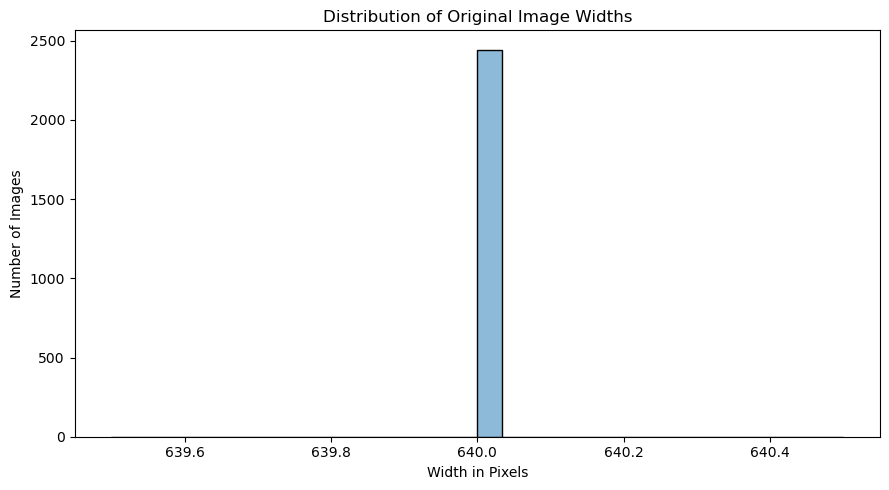

In [11]:
# ==========================================
# Chart 4: Image width distribution
# ==========================================

plt.figure(figsize=(9, 5))
sns.histplot(
    data=image_df,
    x="width",
    bins=30,
    kde=True
)
plt.title("Distribution of Original Image Widths")
plt.xlabel("Width in Pixels")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

## Chart 5 — Image Height Distribution

**Why this chart?**  
This shows whether image heights are consistent or vary significantly.

**Insight:**  
Variation supports the need for a standard model input size such as 224 × 224.

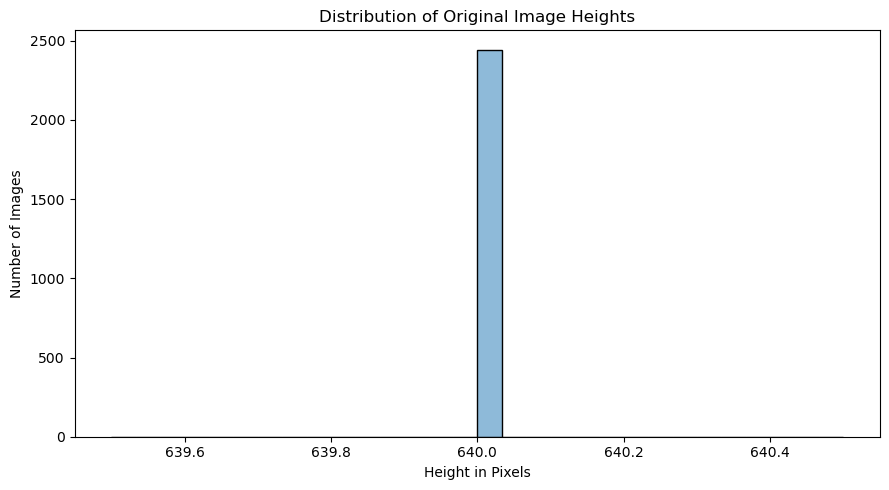

In [12]:
# ==========================================
# Chart 5: Image height distribution
# ==========================================

plt.figure(figsize=(9, 5))
sns.histplot(
    data=image_df,
    x="height",
    bins=30,
    kde=True
)
plt.title("Distribution of Original Image Heights")
plt.xlabel("Height in Pixels")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

## Chart 6 — Aspect Ratio Distribution

**Why this chart?**  
Aspect ratio is width divided by height. It helps identify whether the source images have similar shapes.

**Potential impact:**  
Strong variation can cause geometric distortion when images are resized. The project therefore keeps preprocessing consistent and should be interpreted carefully.

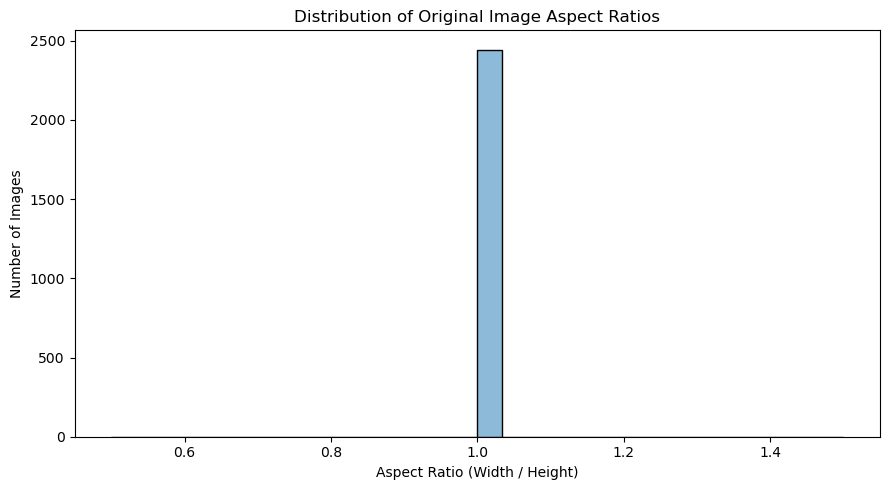

Median aspect ratio: 1.0


In [13]:
# ==========================================
# Chart 6: Aspect ratio distribution
# ==========================================

plt.figure(figsize=(9, 5))
sns.histplot(
    data=image_df,
    x="aspect_ratio",
    bins=30,
    kde=True
)
plt.title("Distribution of Original Image Aspect Ratios")
plt.xlabel("Aspect Ratio (Width / Height)")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

print(
    "Median aspect ratio:",
    round(image_df["aspect_ratio"].median(), 3)
)

## Chart 7 — Aspect Ratio by Class

**Why this chart?**  
A box plot compares the distribution of aspect ratios across classes.

**Insight:**  
If one class has a noticeably different aspect-ratio distribution, the model may learn image-shape differences in addition to medically relevant visual patterns.

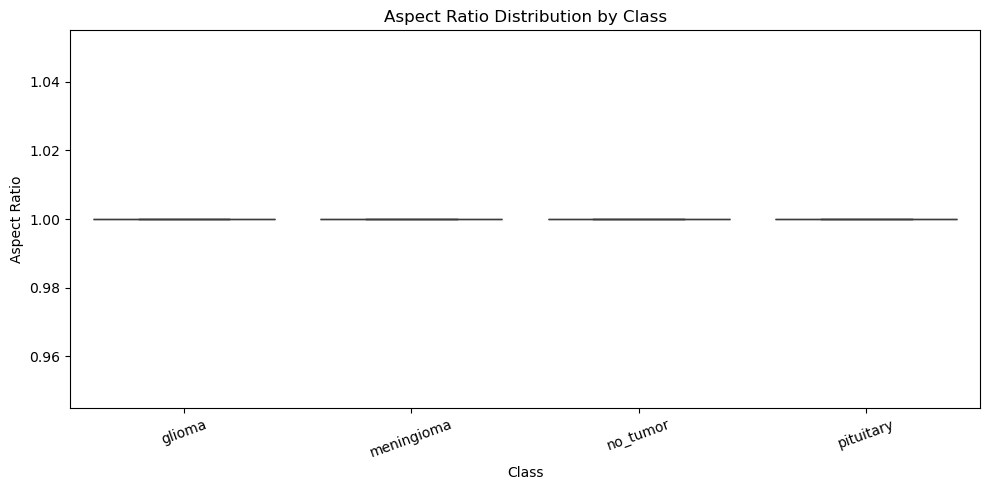

In [14]:
# ==========================================
# Chart 7: Aspect ratio by class
# ==========================================

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=image_df,
    x="class",
    y="aspect_ratio",
    hue="class",
    legend=False
)
plt.title("Aspect Ratio Distribution by Class")
plt.xlabel("Class")
plt.ylabel("Aspect Ratio")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Chart 8 — Brightness Distribution

**Why this chart?**  
Brightness is a simple image-quality characteristic. It can reveal whether the dataset contains very dark or very bright images.

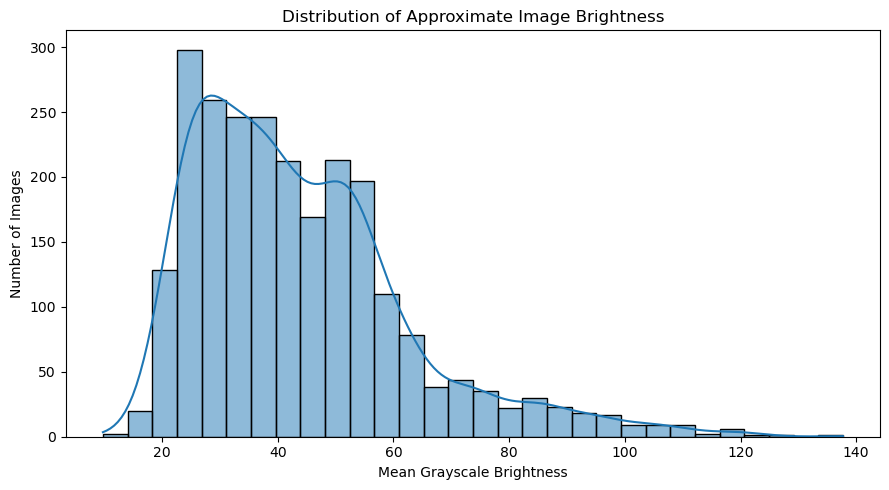

In [15]:
# ==========================================
# Chart 8: Overall brightness distribution
# ==========================================

plt.figure(figsize=(9, 5))
sns.histplot(
    data=image_df,
    x="brightness",
    bins=30,
    kde=True
)
plt.title("Distribution of Approximate Image Brightness")
plt.xlabel("Mean Grayscale Brightness")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

## Chart 9 — Brightness by Class

**Why this chart?**  
A box plot allows class-wise comparison of brightness.

**Potential impact:**  
If classes have very different brightness patterns, augmentation and normalization can help reduce dependence on simple lighting/intensity differences.

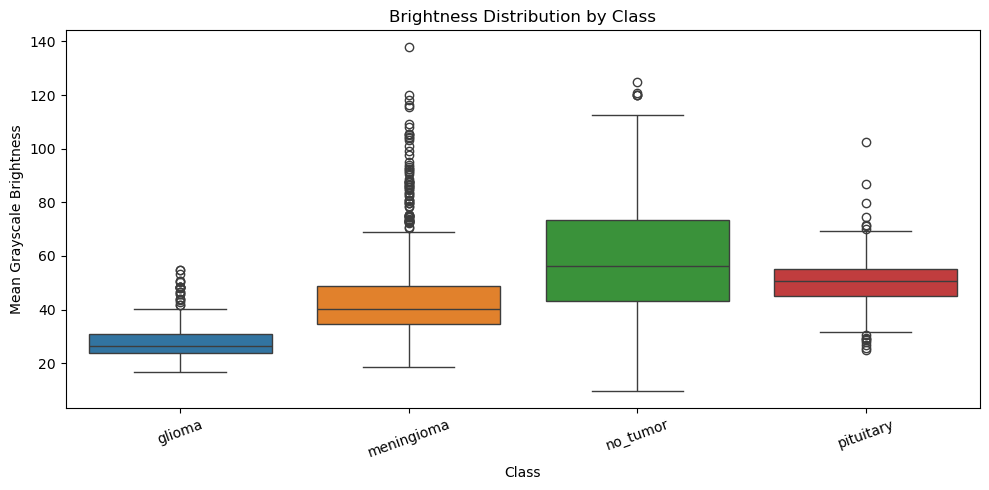

In [16]:
# ==========================================
# Chart 9: Brightness by class
# ==========================================

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=image_df,
    x="class",
    y="brightness",
    hue="class",
    legend=False
)
plt.title("Brightness Distribution by Class")
plt.xlabel("Class")
plt.ylabel("Mean Grayscale Brightness")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## Chart 10 — Mean Image Width by Class

**Why this chart?**  
A class-wise mean comparison checks whether certain classes systematically contain different source resolutions.

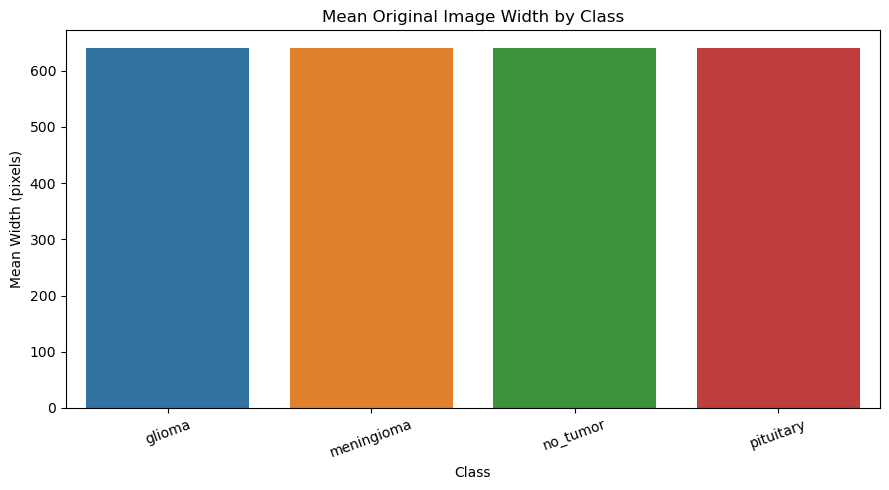

,mean_width
class,
glioma,640.0
meningioma,640.0
no_tumor,640.0
pituitary,640.0


In [17]:
# ==========================================
# Chart 10: Mean width by class
# ==========================================

mean_width = image_df.groupby("class")["width"].mean().reindex(class_names)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=mean_width.index,
    y=mean_width.values,
    hue=mean_width.index,
    legend=False
)
plt.title("Mean Original Image Width by Class")
plt.xlabel("Class")
plt.ylabel("Mean Width (pixels)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

display(mean_width.round(2).to_frame("mean_width"))

## Chart 11 — Mean Image Height by Class

**Why this chart?**  
This complements the width analysis and helps identify class-wise resolution differences.

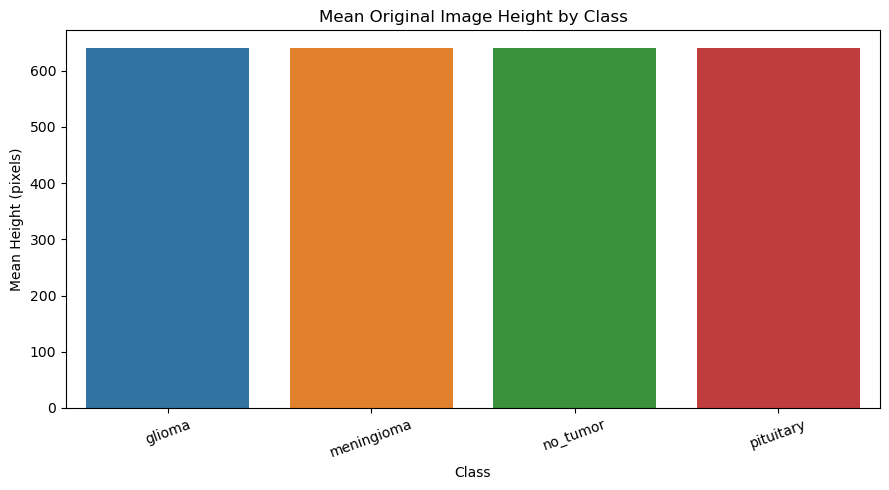

,mean_height
class,
glioma,640.0
meningioma,640.0
no_tumor,640.0
pituitary,640.0


In [18]:
# ==========================================
# Chart 11: Mean height by class
# ==========================================

mean_height = image_df.groupby("class")["height"].mean().reindex(class_names)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=mean_height.index,
    y=mean_height.values,
    hue=mean_height.index,
    legend=False
)
plt.title("Mean Original Image Height by Class")
plt.xlabel("Class")
plt.ylabel("Mean Height (pixels)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

display(mean_height.round(2).to_frame("mean_height"))

## Chart 12 — Sample MRI Images

**Why this chart?**  
A montage of representative images provides direct visual understanding of the classification problem.

**Insight:**  
The classes may have visually overlapping characteristics, which explains why a deep learning model is useful.

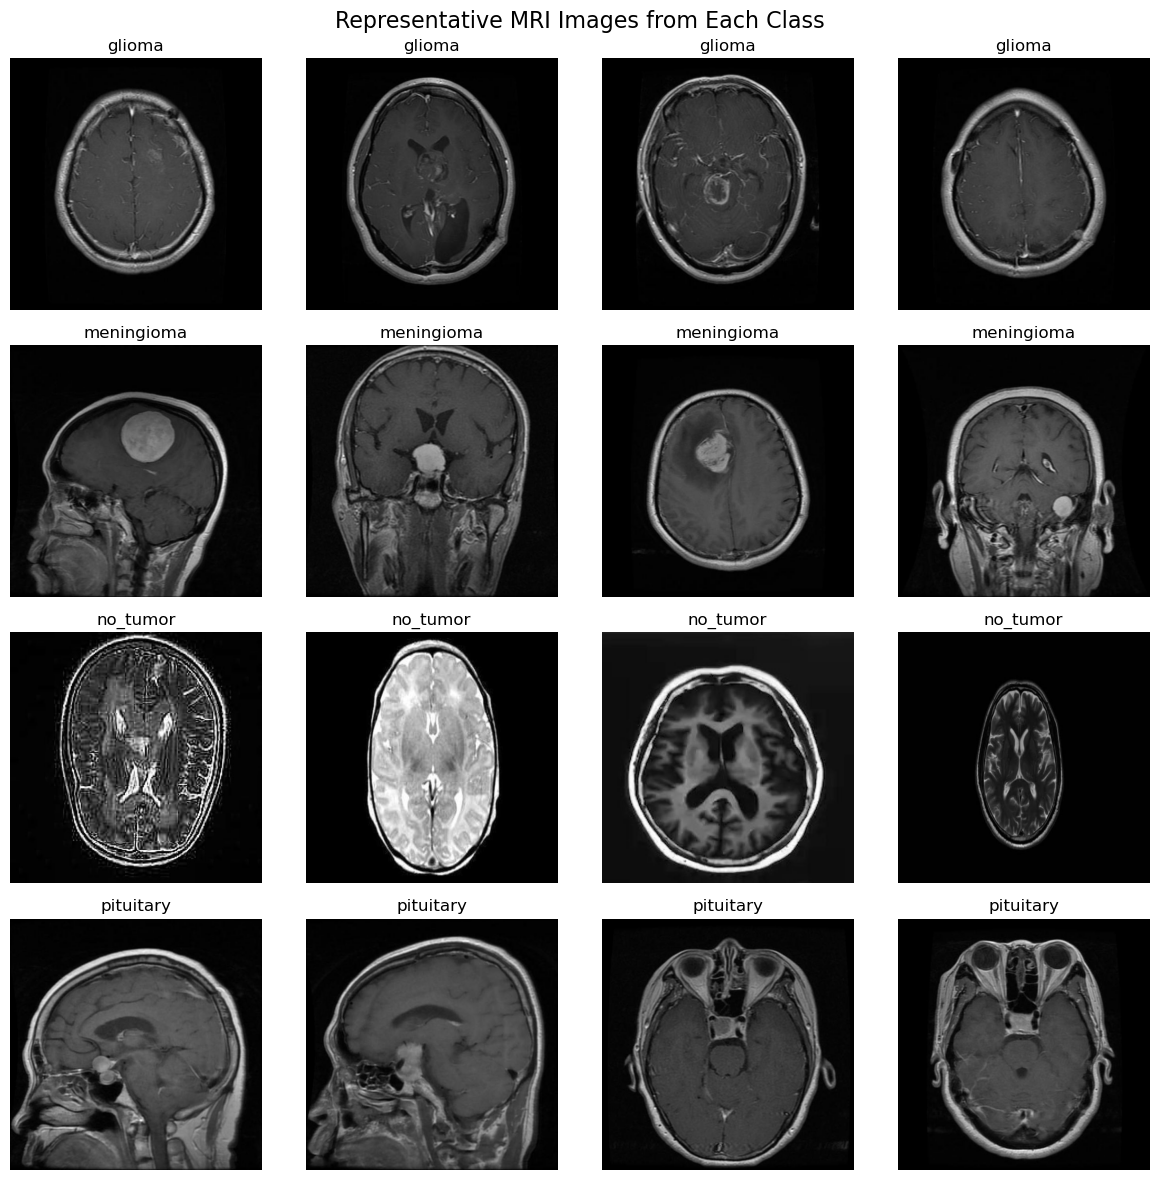

In [19]:
# ==========================================
# Chart 12: Representative MRI images
# ==========================================

fig, axes = plt.subplots(
    nrows=len(class_names),
    ncols=4,
    figsize=(12, 3 * len(class_names))
)

for row_index, class_name in enumerate(class_names):
    class_images = image_df[
        image_df["class"] == class_name
    ]["path"].sample(
        n=min(4, (image_df["class"] == class_name).sum()),
        random_state=SEED
    ).tolist()

    for col_index in range(4):
        ax = axes[row_index, col_index] if len(class_names) > 1 else axes[col_index]

        if col_index < len(class_images):
            img = Image.open(class_images[col_index]).convert("RGB")
            ax.imshow(img)
            ax.set_title(class_name)
        ax.axis("off")

plt.suptitle("Representative MRI Images from Each Class", fontsize=16)
plt.tight_layout()
plt.show()

## Chart 13 — File Extension Distribution

**Why this chart?**  
It verifies which image formats are actually present and helps identify whether preprocessing must handle multiple file types.

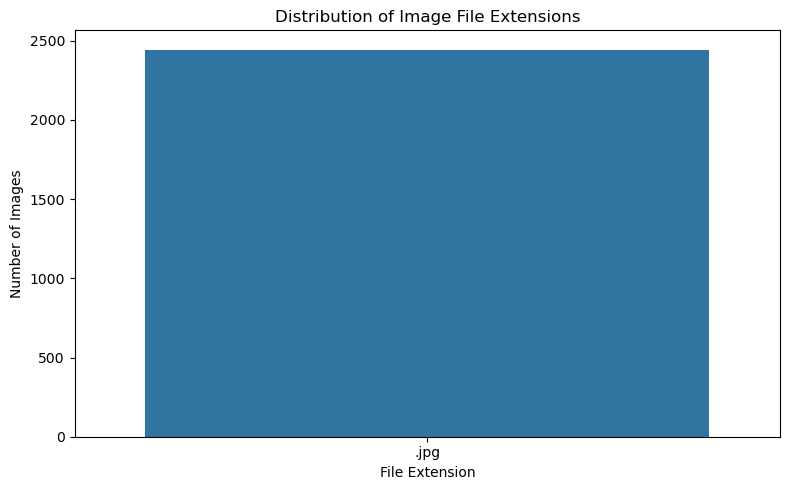

,count
extension,
.jpg,2443


In [20]:
# ==========================================
# Chart 13: Image file extensions
# ==========================================

extension_counts = image_df["extension"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=extension_counts.index,
    y=extension_counts.values,
    hue=extension_counts.index,
    legend=False
)
plt.title("Distribution of Image File Extensions")
plt.xlabel("File Extension")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

display(extension_counts.to_frame("count"))

## Chart 14 — Images per Split

**Why this chart?**  
This verifies the overall train/validation/test proportions.

**Insight:**  
The training set should normally contain the largest share because the model learns from it.

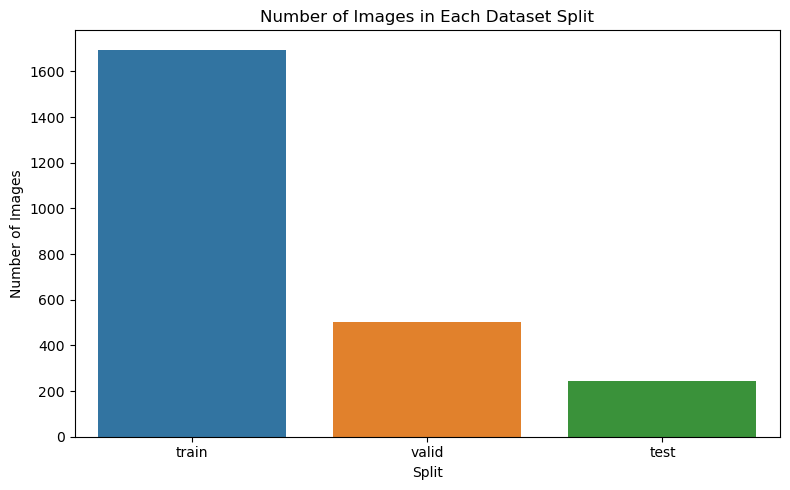

,image_count
split,
train,1695
valid,502
test,246


In [21]:
# ==========================================
# Chart 14: Images per dataset split
# ==========================================

split_counts = image_df["split"].value_counts().reindex(
    ["train", "valid", "test"]
)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=split_counts.index,
    y=split_counts.values,
    hue=split_counts.index,
    legend=False
)
plt.title("Number of Images in Each Dataset Split")
plt.xlabel("Split")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

display(split_counts.to_frame("image_count"))

## Chart 15 — Split Percentage

**Why this chart?**  
Percentages provide an easy-to-read view of the dataset allocation.

**Potential impact:**  
A very small validation or test set can make evaluation unstable. This chart helps confirm that the supplied split is reasonable.

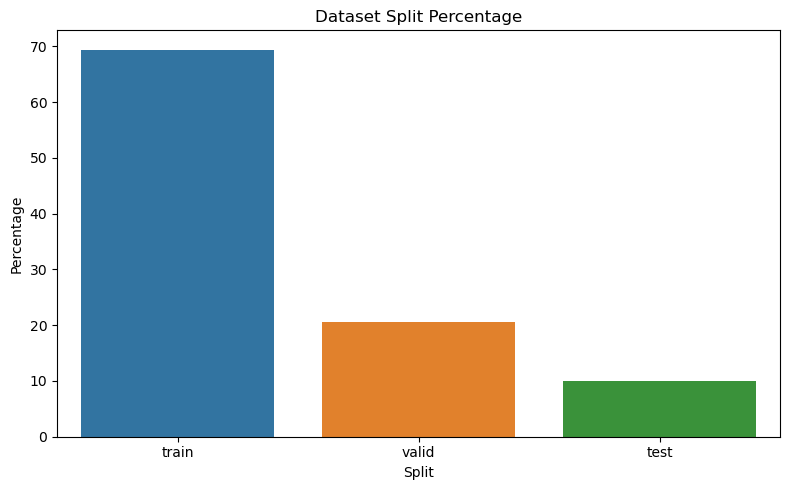

,percentage
split,
train,69.38
valid,20.55
test,10.07


In [22]:
# ==========================================
# Chart 15: Dataset split percentages
# ==========================================

split_percentage = image_df["split"].value_counts(
    normalize=True
).reindex(["train", "valid", "test"]).mul(100)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=split_percentage.index,
    y=split_percentage.values,
    hue=split_percentage.index,
    legend=False
)
plt.title("Dataset Split Percentage")
plt.xlabel("Split")
plt.ylabel("Percentage")
plt.tight_layout()
plt.show()

display(split_percentage.round(2).to_frame("percentage"))

## Chart 16 — Class vs Dataset Split Heatmap

**Why this chart?**  
A heatmap makes it easy to spot classes that are underrepresented in a particular split.

**Insight:**  
Large differences across rows can indicate class imbalance that should be considered during model evaluation.

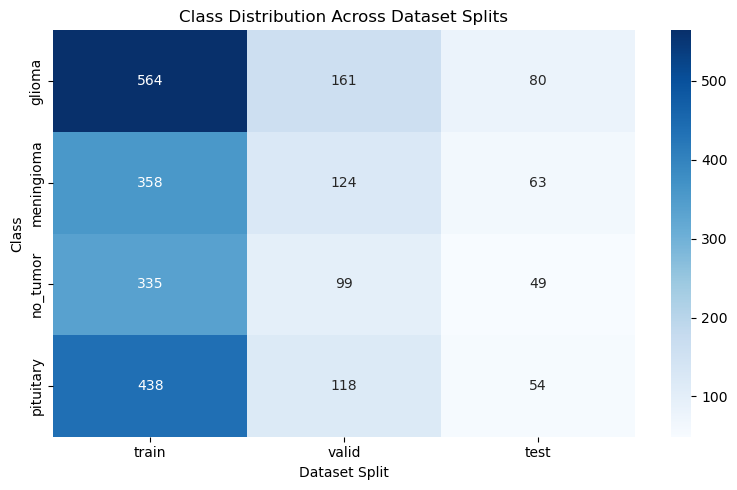

In [23]:
# ==========================================
# Chart 16: Class vs split heatmap
# ==========================================

class_split_table = pd.crosstab(
    image_df["class"],
    image_df["split"]
).reindex(index=class_names, columns=["train", "valid", "test"])

plt.figure(figsize=(8, 5))
sns.heatmap(
    class_split_table,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Class")
plt.tight_layout()
plt.show()

# 10. Data Leakage Check

A very important part of image classification is making sure that the same image is not present in more than one split.

We compare normalized file names/hashes at the path level first. If the source dataset contains copied images with different filenames, a deeper image-hash check can be added as future work.

In [24]:
# ==========================================
# Check for identical file paths across splits
# ==========================================

split_sets = {
    split: set(
        image_df.loc[image_df["split"] == split, "path"]
    )
    for split in ["train", "valid", "test"]
}

print("Train ∩ Validation:", len(split_sets["train"] & split_sets["valid"]))
print("Train ∩ Test:", len(split_sets["train"] & split_sets["test"]))
print("Validation ∩ Test:", len(split_sets["valid"] & split_sets["test"]))

print(
    "\nPath-level leakage check completed. "
    "A deeper perceptual image-hash check can be added if required."
)

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

Path-level leakage check completed. A deeper perceptual image-hash check can be added if required.


# 11. TensorFlow Data Pipeline

We now convert the image folders into TensorFlow datasets.

### Preprocessing

Each image will be:

1. Loaded from disk.
2. Resized to **224 × 224**.
3. Converted to RGB.
4. Converted to floating-point values.
5. Normalized to the range **0–1**.

The training, validation and test datasets are kept separate.

In [25]:
# ==========================================
# Create TensorFlow datasets from directories
# ==========================================

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="int",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR / "valid",
    labels="inferred",
    label_mode="int",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR / "test",
    labels="inferred",
    label_mode="int",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("TensorFlow datasets created successfully.")

Found 1695 files belonging to 4 classes.
Found 502 files belonging to 4 classes.
Found 246 files belonging to 4 classes.
TensorFlow datasets created successfully.


## 11.1 Normalize Images

Pixel values originally range approximately from 0 to 255.

Dividing by 255 converts them to 0–1, which generally makes neural-network optimization more stable.

In [26]:
# ==========================================
# Normalize pixel values to 0-1
# ==========================================

def normalize_images(images, labels):
    # Convert integer pixel values to float32 and scale to [0, 1].
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

train_ds = train_ds.map(
    normalize_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

valid_ds = valid_ds.map(
    normalize_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    normalize_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Cache and prefetch improve input efficiency during training.
train_ds = train_ds.cache().prefetch(tf.data.AUTOTUNE)
valid_ds = valid_ds.cache().prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.cache().prefetch(tf.data.AUTOTUNE)

print("Normalization and input pipeline optimization completed.")

Normalization and input pipeline optimization completed.


# 12. Data Augmentation

Deep learning models can overfit when the training data is limited.

We therefore apply realistic augmentation only to training images:

- Horizontal flip.
- Small rotation.
- Zoom.
- Translation.
- Contrast adjustment.

The validation and test images are **not** augmented because they should represent the original evaluation data.

In [27]:
# ==========================================
# Data augmentation pipeline
# ==========================================

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.10),
        layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05
        ),
        layers.RandomContrast(0.10),
    ],
    name="data_augmentation"
)

print(data_augmentation)

<Sequential name=data_augmentation, built=False>


## Chart 17 — Augmentation Examples

**Why this chart?**  
It visually confirms that augmentation changes the training images while preserving their general structure.

**Important:**  
Augmentation should create realistic variations. Excessive transformation could destroy useful medical image features.

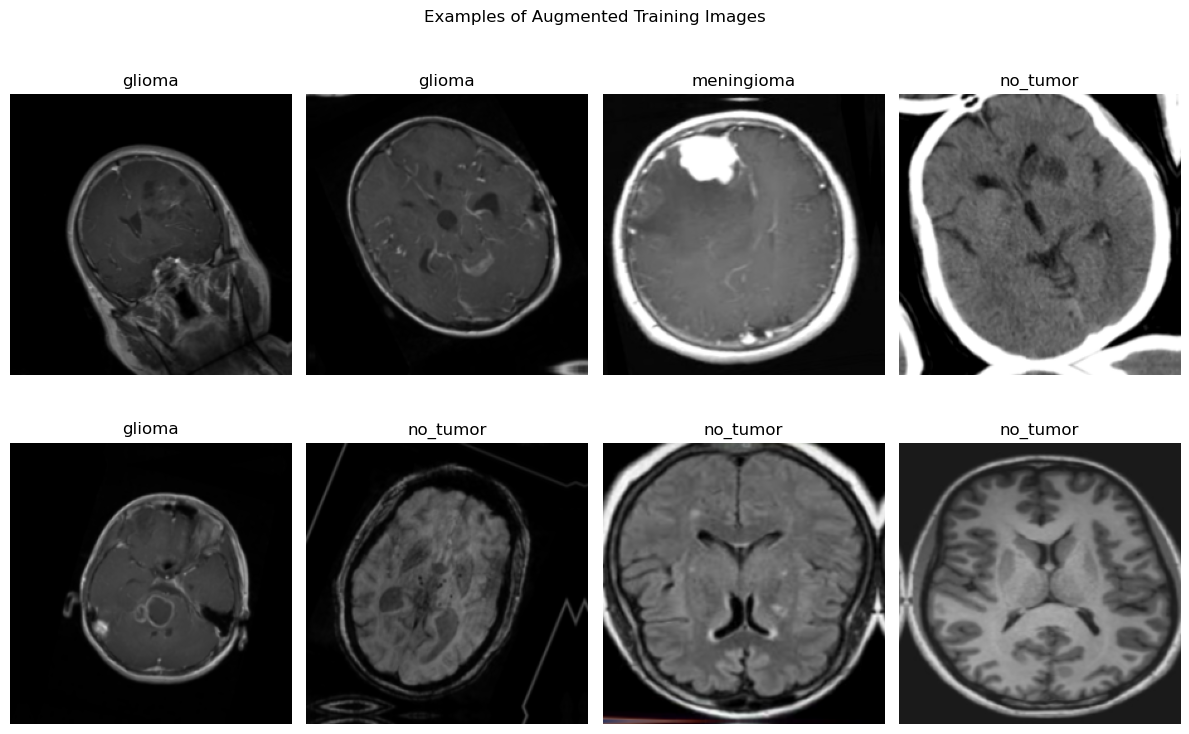

In [28]:
# ==========================================
# Chart 17: Augmented image examples
# ==========================================

sample_images, sample_labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(min(8, len(sample_images))):
    augmented = data_augmentation(
        tf.expand_dims(sample_images[i], axis=0),
        training=True
    )[0]

    plt.subplot(2, 4, i + 1)
    plt.imshow(tf.clip_by_value(augmented, 0, 1))
    plt.title(class_names[int(sample_labels[i])])
    plt.axis("off")

plt.suptitle("Examples of Augmented Training Images")
plt.tight_layout()
plt.show()

# 13. Class Weights

If classes are imbalanced, the model may focus too heavily on the majority class.

Class weights give additional importance to minority classes during training.

The weights are calculated from the training-set class counts only.

In [29]:
# ==========================================
# Calculate class weights
# ==========================================

train_counts = (
    train_meta["class"]
    .value_counts()
    .reindex(class_names)
)

total_train = train_counts.sum()
num_classes = len(class_names)

class_weights = {
    index: float(total_train / (num_classes * count))
    for index, count in enumerate(train_counts)
}

print("Training class counts:")
display(train_counts.to_frame("count"))

print("\nClass weights:")
for index, weight in class_weights.items():
    print(f"{index} - {class_names[index]}: {weight:.4f}")

Training class counts:


,count
class,
glioma,564
meningioma,358
no_tumor,335
pituitary,438



Class weights:
0 - glioma: 0.7513
1 - meningioma: 1.1837
2 - no_tumor: 1.2649
3 - pituitary: 0.9675


# 14. Custom CNN — Baseline Model

A Convolutional Neural Network (CNN) is well suited to image classification because convolutional layers can learn spatial patterns such as edges, textures and shapes.

### Architecture

The custom CNN contains:

- Convolution layers.
- Batch Normalization.
- Max Pooling.
- Global Average Pooling.
- Dense layer.
- Dropout.
- Softmax output layer.

Dropout helps reduce overfitting, while Batch Normalization can stabilize training.

In [30]:
# ==========================================
# Build the custom CNN model
# ==========================================

def build_custom_cnn(input_shape=(224, 224, 3), num_classes=4):
    model = keras.Sequential(
        [
            layers.Input(shape=input_shape),

            # Data augmentation is active only during training.
            data_augmentation,

            # First convolution block.
            layers.Conv2D(32, 3, padding="same", activation="relu"),
            layers.BatchNormalization(),
            layers.MaxPooling2D(),

            # Second convolution block.
            layers.Conv2D(64, 3, padding="same", activation="relu"),
            layers.BatchNormalization(),
            layers.MaxPooling2D(),

            # Third convolution block.
            layers.Conv2D(128, 3, padding="same", activation="relu"),
            layers.BatchNormalization(),
            layers.MaxPooling2D(),

            # Fourth convolution block.
            layers.Conv2D(256, 3, padding="same", activation="relu"),
            layers.BatchNormalization(),
            layers.MaxPooling2D(),

            # Convert feature maps into a compact vector.
            layers.GlobalAveragePooling2D(),

            # Fully connected classification layer.
            layers.Dense(128, activation="relu"),

            # Dropout reduces overfitting.
            layers.Dropout(0.50),

            # Final softmax gives probability for each class.
            layers.Dense(num_classes, activation="softmax")
        ],
        name="Custom_CNN"
    )

    return model

custom_cnn = build_custom_cnn(
    input_shape=(*IMG_SIZE, 3),
    num_classes=len(class_names)
)

custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

custom_cnn.summary()

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,748 (1.62 MB)

 Trainable params: 422,788 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

# 15. Training Callbacks

We use three callbacks:

- **EarlyStopping:** stops training when validation loss stops improving.
- **ReduceLROnPlateau:** lowers the learning rate when validation loss plateaus.
- **ModelCheckpoint:** saves the best custom CNN based on validation accuracy.

This reduces unnecessary training and helps keep the best model.

In [31]:
# ==========================================
# Callbacks for custom CNN training
# ==========================================

custom_checkpoint = MODEL_DIR / "custom_cnn_best.keras"

custom_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        filepath=str(custom_checkpoint),
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]

print("Callbacks configured.")

Callbacks configured.


# 16. Train the Custom CNN

The custom CNN is now trained on the training dataset and evaluated after every epoch using the validation dataset.

> Training time depends strongly on the available CPU/GPU. If your computer is slow, reduce `INITIAL_EPOCHS`.

In [32]:
# ==========================================
# Train the custom CNN
# ==========================================

custom_history = custom_cnn.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=INITIAL_EPOCHS,
    class_weight=class_weights,
    callbacks=custom_callbacks
)

print("Custom CNN training completed.")

Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6755 - loss: 0.9051
Epoch 1: val_accuracy improved from None to 0.23506, saving model to outputs\models\custom_cnn_best.keras

Epoch 1: finished saving model to outputs\models\custom_cnn_best.keras
53/53 ━━━━━━━━━━━━━━━━━━━━ 123s 2s/step - accuracy: 0.6755 - loss: 0.9051 - val_accuracy: 0.2351 - val_loss: 1.7873 - learning_rate: 0.0010
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7304 - loss: 0.7405
Epoch 2: val_accuracy improved from 0.23506 to 0.45020, saving model to outputs\models\custom_cnn_best.keras

Epoch 2: finished saving model to outputs\models\custom_cnn_best.keras
53/53 ━━━━━━━━━━━━━━━━━━━━ 122s 2s/step - accuracy: 0.7304 - loss: 0.7405 - val_accuracy: 0.4502 - val_loss: 1.5477 - learning_rate: 0.0010
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7463 - loss: 0.6704
Epoch 3: val_accuracy improved from 0.45020 to 0.53586, saving model to outputs\models\custom_cnn_best.keras

Ep

## Chart 18 — Custom CNN Accuracy

**Why this chart?**  
Training and validation accuracy reveal whether the model is learning and whether it may be overfitting.

**Interpretation:**
- Both curves increasing → learning is occurring.
- Training accuracy much higher than validation accuracy → possible overfitting.
- Both remaining low → possible underfitting.

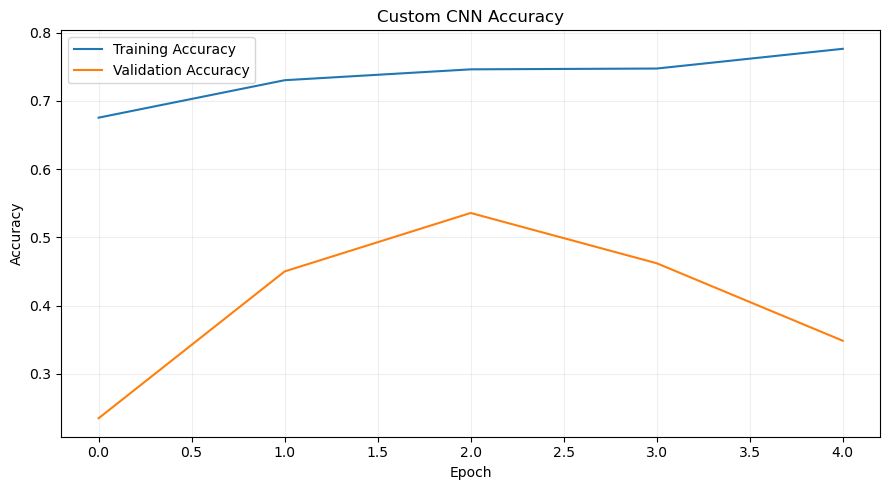

In [33]:
# ==========================================
# Chart 18: Custom CNN accuracy
# ==========================================

plt.figure(figsize=(9, 5))
plt.plot(custom_history.history["accuracy"], label="Training Accuracy")
plt.plot(custom_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Custom CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Chart 19 — Custom CNN Loss

**Why this chart?**  
Loss measures how far predictions are from the true labels.

A rising validation loss while training loss continues to fall is a common sign of overfitting.

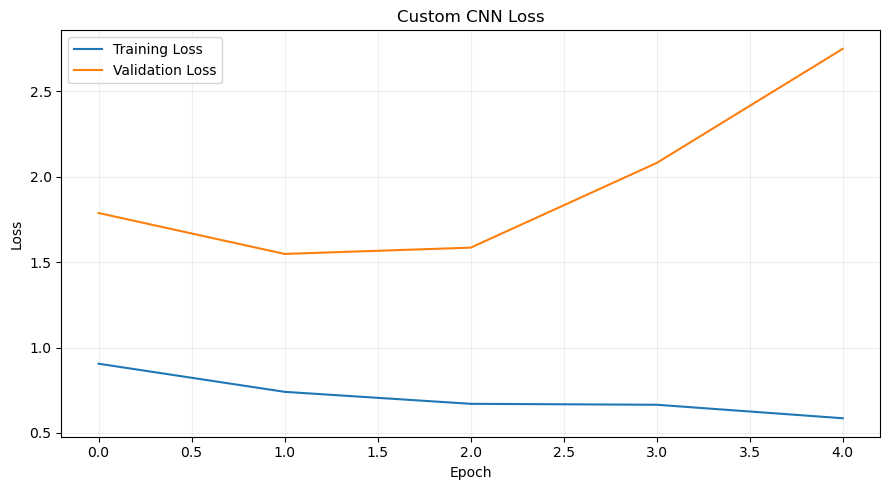

In [34]:
# ==========================================
# Chart 19: Custom CNN loss
# ==========================================

plt.figure(figsize=(9, 5))
plt.plot(custom_history.history["loss"], label="Training Loss")
plt.plot(custom_history.history["val_loss"], label="Validation Loss")
plt.title("Custom CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# 17. Model Evaluation Functions

Accuracy alone is not enough for a multi-class medical-image experiment.

We calculate:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Classification report
- Confusion matrix

Macro averaging gives each class equal importance.

In [35]:
# ==========================================
# Helper function for model evaluation
# ==========================================

def get_predictions(model, dataset):
    """Return true labels and predicted labels for a dataset."""

    true_labels = []
    predicted_labels = []

    for images, labels in dataset:
        probabilities = model.predict(images, verbose=0)
        predictions = np.argmax(probabilities, axis=1)

        true_labels.extend(labels.numpy())
        predicted_labels.extend(predictions)

    return np.array(true_labels), np.array(predicted_labels)


def evaluate_model(model, dataset, model_name):
    """Calculate standard classification metrics."""

    y_true, y_pred = get_predictions(model, dataset)

    metrics_dict = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

    print(f"\n===== {model_name} =====")
    print(f"Accuracy       : {metrics_dict['Accuracy']:.4f}")
    print(f"Macro Precision: {metrics_dict['Macro Precision']:.4f}")
    print(f"Macro Recall   : {metrics_dict['Macro Recall']:.4f}")
    print(f"Macro F1       : {metrics_dict['Macro F1']:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            y_pred,
            target_names=class_names,
            zero_division=0
        )
    )

    return metrics_dict, y_true, y_pred

## Chart 20 — Custom CNN Confusion Matrix

**Why this chart?**  
A confusion matrix shows exactly which classes are being confused.

**Potential impact:**  
If one class is frequently predicted as another class, overall accuracy may hide an important weakness. Class-level errors should therefore be examined.


===== Custom CNN =====
Accuracy       : 0.4187
Macro Precision: 0.5289
Macro Recall   : 0.4036
Macro F1       : 0.2967

Classification Report:
              precision    recall  f1-score   support

      glioma       0.83      0.61      0.71        80
  meningioma       0.00      0.00      0.00        63
    no_tumor       1.00      0.02      0.04        49
   pituitary       0.28      0.98      0.44        54

    accuracy                           0.42       246
   macro avg       0.53      0.40      0.30       246
weighted avg       0.53      0.42      0.33       246



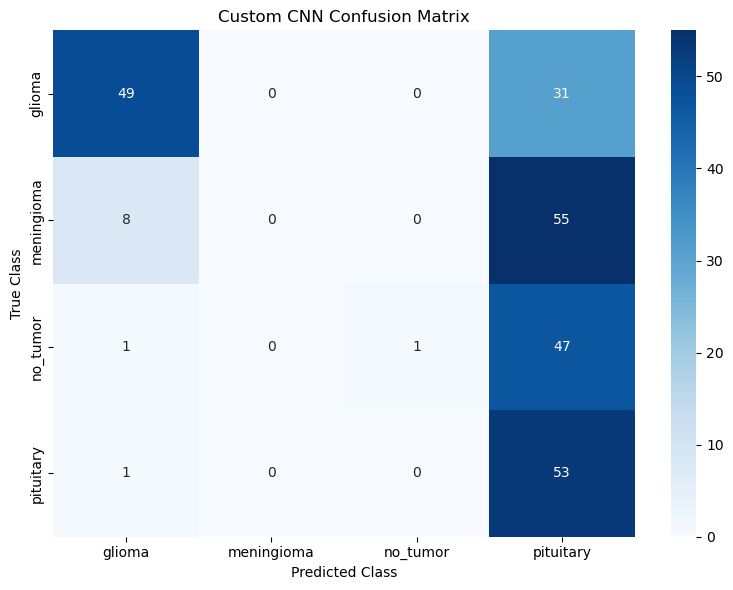

In [36]:
# ==========================================
# Evaluate custom CNN
# ==========================================

custom_metrics, custom_y_true, custom_y_pred = evaluate_model(
    custom_cnn,
    test_ds,
    "Custom CNN"
)

custom_cm = confusion_matrix(
    custom_y_true,
    custom_y_pred
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    custom_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Custom CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

# 18. Transfer Learning with MobileNetV2

Transfer learning starts with a model that has already learned useful visual features from ImageNet.

### Why MobileNetV2?

MobileNetV2 is relatively lightweight compared with many large architectures, making it practical for:

- Local experimentation.
- Faster training.
- Streamlit deployment.
- Resource-constrained environments.

The pretrained convolutional base is initially frozen. A new classification head is trained for our four MRI classes.

In [37]:
# ==========================================
# Build MobileNetV2 transfer-learning model
# ==========================================

def build_transfer_model(num_classes):
    # Load ImageNet pretrained MobileNetV2 without its original classifier.
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(*IMG_SIZE, 3),
        include_top=False,
        weights="imagenet"
    )

    # Freeze pretrained layers during the initial training phase.
    base_model.trainable = False

    inputs = layers.Input(shape=(*IMG_SIZE, 3))

    # Apply the same augmentation strategy used for the custom CNN.
    x = data_augmentation(inputs)

    # MobileNetV2 expects inputs in the range [-1, 1].
    x = layers.Rescaling(255.0)(x)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

    # Extract pretrained visual features.
    x = base_model(x, training=False)

    # Reduce feature maps to one feature vector.
    x = layers.GlobalAveragePooling2D()(x)

    # New task-specific classification head.
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.40)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    model = keras.Model(
        inputs,
        outputs,
        name="MobileNetV2_Transfer_Learning"
    )

    return model, base_model

transfer_model, base_model = build_transfer_model(
    num_classes=len(class_names)
)

transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

transfer_model.summary()

Model: "MobileNetV2_Transfer_Learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# 19. Train the Transfer Learning Model

Only the new classification head is trained in this stage.

This is usually faster and safer than immediately fine-tuning all pretrained layers.

In [38]:
# ==========================================
# Callbacks for transfer learning
# ==========================================

transfer_checkpoint = MODEL_DIR / "mobilenetv2_best.keras"

transfer_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        filepath=str(transfer_checkpoint),
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]

# ==========================================
# Train transfer-learning model
# ==========================================

transfer_history = transfer_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=INITIAL_EPOCHS,
    class_weight=class_weights,
    callbacks=transfer_callbacks
)

print("Transfer-learning training completed.")

Epoch 1/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 561ms/step - accuracy: 0.6767 - loss: 0.8520
Epoch 1: val_accuracy improved from None to 0.76494, saving model to outputs\models\mobilenetv2_best.keras

Epoch 1: finished saving model to outputs\models\mobilenetv2_best.keras
53/53 ━━━━━━━━━━━━━━━━━━━━ 46s 729ms/step - accuracy: 0.6767 - loss: 0.8520 - val_accuracy: 0.7649 - val_loss: 0.5735 - learning_rate: 0.0010
Epoch 2/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 515ms/step - accuracy: 0.8484 - loss: 0.4399
Epoch 2: val_accuracy did not improve from 0.76494
53/53 ━━━━━━━━━━━━━━━━━━━━ 34s 639ms/step - accuracy: 0.8484 - loss: 0.4399 - val_accuracy: 0.7610 - val_loss: 0.6164 - learning_rate: 0.0010
Epoch 3/10
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 708ms/step - accuracy: 0.8637 - loss: 0.3864
Epoch 3: val_accuracy improved from 0.76494 to 0.77092, saving model to outputs\models\mobilenetv2_best.keras

Epoch 3: finished saving model to outputs\models\mobilenetv2_best.keras
53/53 ━━━━━━━━━━━━━━━━━━━━ 48s 908ms/step - 

## Chart 21 — Transfer Learning Accuracy

This chart compares training and validation accuracy during transfer learning.

The goal is to achieve strong validation performance without a large gap between training and validation accuracy.

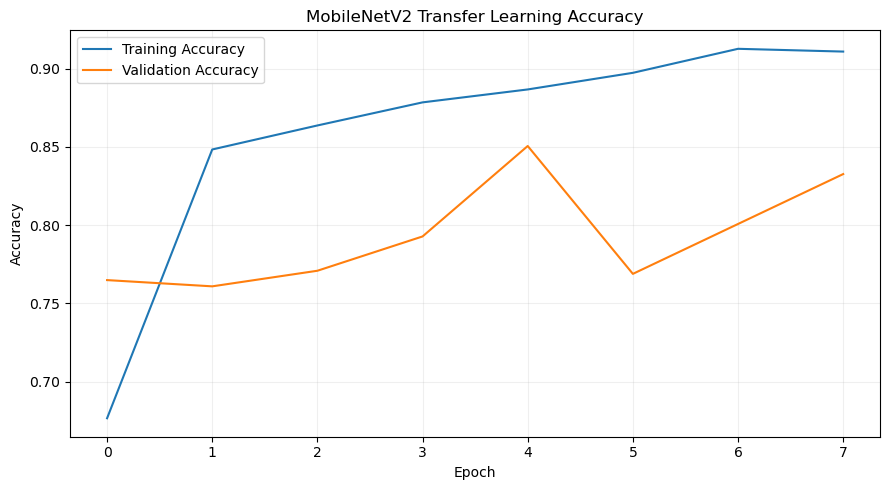

In [39]:
# ==========================================
# Chart 21: Transfer learning accuracy
# ==========================================

plt.figure(figsize=(9, 5))
plt.plot(
    transfer_history.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    transfer_history.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.title("MobileNetV2 Transfer Learning Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Chart 22 — Transfer Learning Loss

The loss curves help us identify whether the model is still improving or beginning to overfit.

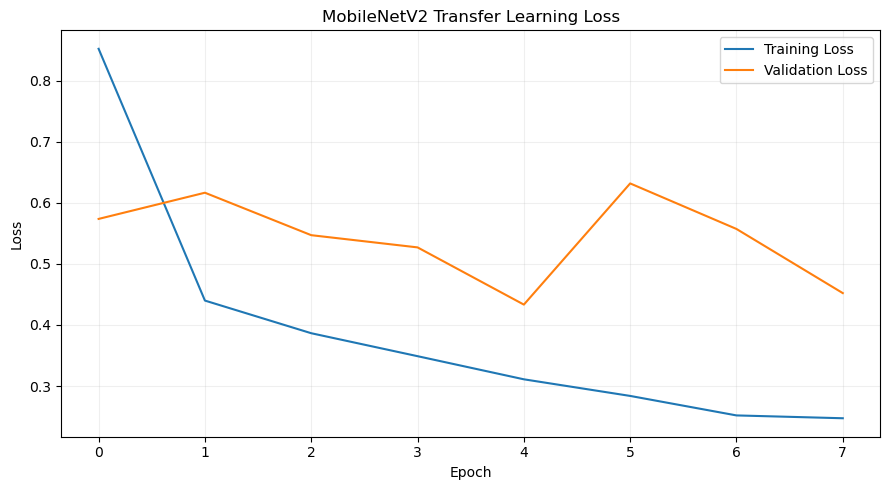

In [40]:
# ==========================================
# Chart 22: Transfer learning loss
# ==========================================

plt.figure(figsize=(9, 5))
plt.plot(
    transfer_history.history["loss"],
    label="Training Loss"
)
plt.plot(
    transfer_history.history["val_loss"],
    label="Validation Loss"
)
plt.title("MobileNetV2 Transfer Learning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# 20. Fine-Tuning the Pretrained Model

After the classification head has learned the task, we unfreeze only the later layers of MobileNetV2.

Fine-tuning allows the model to adapt high-level pretrained visual features to MRI images.

A very small learning rate is used to avoid destroying useful pretrained features.

In [41]:
# ==========================================
# Fine-tune the last part of MobileNetV2
# ==========================================

base_model.trainable = True

# Freeze most early layers and fine-tune only the final 30 layers.
fine_tune_from = max(0, len(base_model.layers) - 30)

for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for more stable fine-tuning.
for layer in base_model.layers[fine_tune_from:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Recompile is required after changing trainable layers.
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

trainable_count = sum(
    int(layer.trainable)
    for layer in transfer_model.layers
)

print("Number of trainable model layers:", trainable_count)

Number of trainable model layers: 8


# 21. Fine-Tuning Training

Fine-tuning uses fewer epochs and a much smaller learning rate than the initial transfer-learning stage.

In [42]:
# ==========================================
# Fine-tuning callbacks
# ==========================================

fine_tune_checkpoint = MODEL_DIR / "mobilenetv2_finetuned_best.keras"

fine_tune_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        filepath=str(fine_tune_checkpoint),
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]

fine_tune_history = transfer_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=FINE_TUNE_EPOCHS,
    class_weight=class_weights,
    callbacks=fine_tune_callbacks
)

print("Fine-tuning completed.")

Epoch 1/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.9103 - loss: 0.2521
Epoch 1: val_accuracy improved from None to 0.84661, saving model to outputs\models\mobilenetv2_finetuned_best.keras

Epoch 1: finished saving model to outputs\models\mobilenetv2_finetuned_best.keras
53/53 ━━━━━━━━━━━━━━━━━━━━ 301s 6s/step - accuracy: 0.9103 - loss: 0.2521 - val_accuracy: 0.8466 - val_loss: 0.4363
Epoch 2/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 931ms/step - accuracy: 0.9074 - loss: 0.2337
Epoch 2: val_accuracy improved from 0.84661 to 0.85458, saving model to outputs\models\mobilenetv2_finetuned_best.keras

Epoch 2: finished saving model to outputs\models\mobilenetv2_finetuned_best.keras
53/53 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - accuracy: 0.9074 - loss: 0.2337 - val_accuracy: 0.8546 - val_loss: 0.4170
Epoch 3/5
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 920ms/step - accuracy: 0.9156 - loss: 0.2222
Epoch 3: val_accuracy improved from 0.85458 to 0.86454, saving model to outputs\models\mobilenetv2_finetuned_best.

## Chart 23 — Fine-Tuning Accuracy

This chart shows whether fine-tuning improves validation performance after adapting pretrained features to the target dataset.

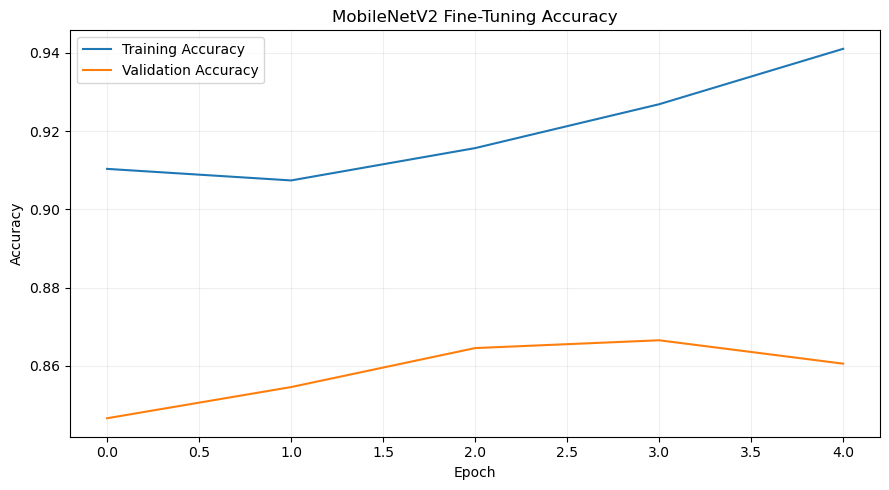

In [43]:
# ==========================================
# Chart 23: Fine-tuning accuracy
# ==========================================

plt.figure(figsize=(9, 5))
plt.plot(
    fine_tune_history.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    fine_tune_history.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.title("MobileNetV2 Fine-Tuning Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Chart 24 — Fine-Tuning Loss

This chart shows whether validation loss continues to improve after fine-tuning.

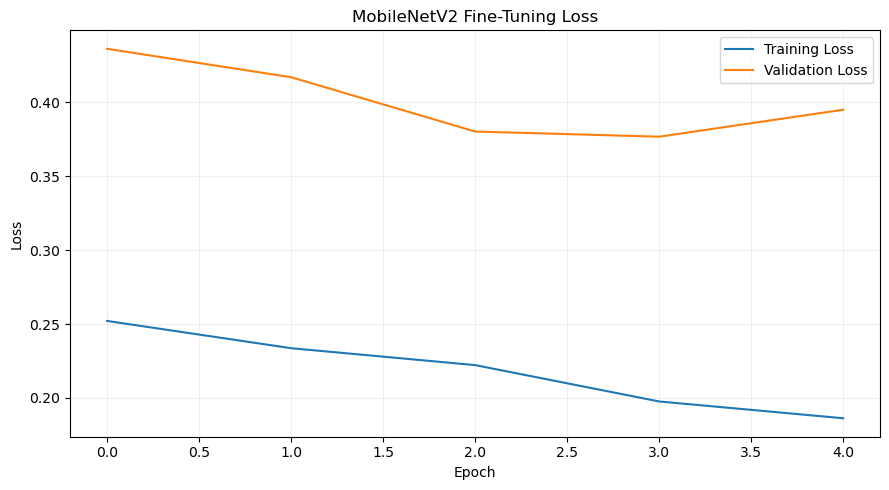

In [44]:
# ==========================================
# Chart 24: Fine-tuning loss
# ==========================================

plt.figure(figsize=(9, 5))
plt.plot(
    fine_tune_history.history["loss"],
    label="Training Loss"
)
plt.plot(
    fine_tune_history.history["val_loss"],
    label="Validation Loss"
)
plt.title("MobileNetV2 Fine-Tuning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Chart 25 — Fine-Tuned Transfer Model Confusion Matrix

The confusion matrix is especially important here because the model is being used for four different classes.


===== MobileNetV2 Fine-Tuned =====
Accuracy       : 0.8577
Macro Precision: 0.8625
Macro Recall   : 0.8565
Macro F1       : 0.8541

Classification Report:
              precision    recall  f1-score   support

      glioma       0.92      0.90      0.91        80
  meningioma       0.79      0.73      0.76        63
    no_tumor       0.95      0.80      0.87        49
   pituitary       0.78      1.00      0.88        54

    accuracy                           0.86       246
   macro avg       0.86      0.86      0.85       246
weighted avg       0.86      0.86      0.86       246



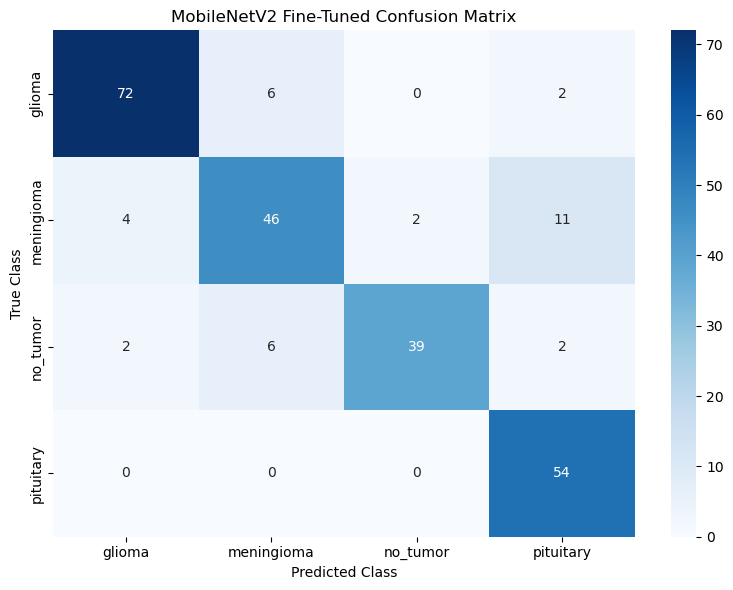

In [45]:
# ==========================================
# Evaluate the fine-tuned transfer model
# ==========================================

transfer_metrics, transfer_y_true, transfer_y_pred = evaluate_model(
    transfer_model,
    test_ds,
    "MobileNetV2 Fine-Tuned"
)

transfer_cm = confusion_matrix(
    transfer_y_true,
    transfer_y_pred
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    transfer_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("MobileNetV2 Fine-Tuned Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

# 22. Model Comparison

We compare the custom CNN and the fine-tuned MobileNetV2 using:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1

For a multi-class medical-image experiment, macro F1 and macro recall are particularly useful because they give equal importance to every class.

In [46]:
# ==========================================
# Create model comparison table
# ==========================================

comparison_df = pd.DataFrame(
    [custom_metrics, transfer_metrics]
)

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Macro Precision": "{:.4f}",
        "Macro Recall": "{:.4f}",
        "Macro F1": "{:.4f}"
    })
)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Custom CNN,0.4187,0.5289,0.4036,0.2967
1,MobileNetV2 Fine-Tuned,0.8577,0.8625,0.8565,0.8541


## Chart 26 — Model Metric Comparison

**Why this chart?**  
A grouped bar chart provides a direct comparison between the two models.

**Interpretation:**  
The best model should not be selected from accuracy alone. Macro F1 and macro recall should also be considered.

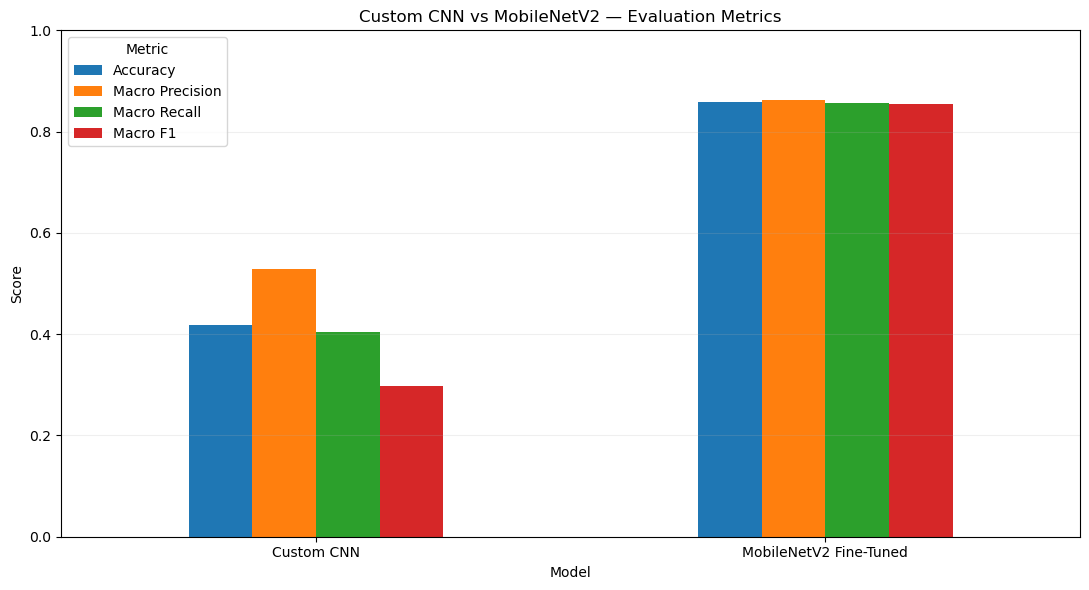

In [47]:
# ==========================================
# Chart 26: Model comparison
# ==========================================

comparison_plot = comparison_df.set_index("Model")

ax = comparison_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Custom CNN vs MobileNetV2 — Evaluation Metrics")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## Chart 27 — Per-Class F1 Comparison

**Why this chart?**  
A model can have a good overall score while performing poorly on one particular class.

This chart therefore compares F1-score for each class.

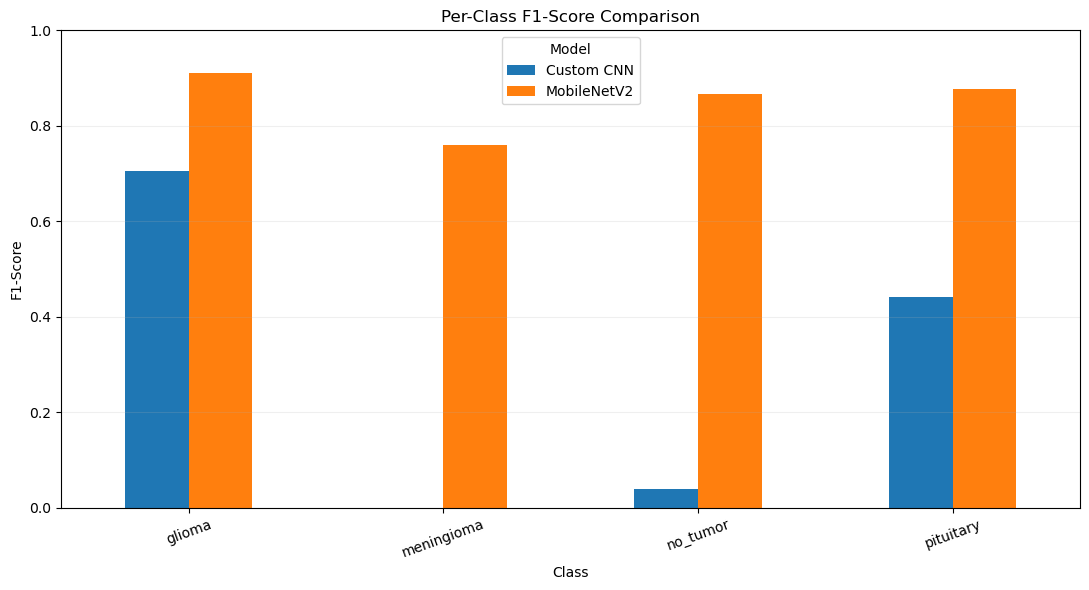

,Custom CNN,MobileNetV2
glioma,0.7050,0.9114
meningioma,0.0000,0.7603
no_tumor,0.0400,0.8667
pituitary,0.4417,0.8780


In [48]:
# ==========================================
# Chart 27: Per-class F1 comparison
# ==========================================

custom_report = classification_report(
    custom_y_true,
    custom_y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

transfer_report = classification_report(
    transfer_y_true,
    transfer_y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

per_class_f1 = pd.DataFrame({
    "Custom CNN": [
        custom_report[c]["f1-score"] for c in class_names
    ],
    "MobileNetV2": [
        transfer_report[c]["f1-score"] for c in class_names
    ]
}, index=class_names)

per_class_f1.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Per-Class F1-Score Comparison")
plt.xlabel("Class")
plt.ylabel("F1-Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(title="Model")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

display(per_class_f1.round(4))

# 23. Model Selection

The following code automatically selects the model with the higher **Macro F1-score**.

This avoids manually choosing a model before seeing the actual test results.

In [49]:
# ==========================================
# Select final model using Macro F1
# ==========================================

if transfer_metrics["Macro F1"] >= custom_metrics["Macro F1"]:
    final_model = transfer_model
    final_model_name = "MobileNetV2 Fine-Tuned"
    final_y_true = transfer_y_true
    final_y_pred = transfer_y_pred
else:
    final_model = custom_cnn
    final_model_name = "Custom CNN"
    final_y_true = custom_y_true
    final_y_pred = custom_y_pred

print("Selected final model:", final_model_name)
print("Reason: highest Macro F1-score among the evaluated models.")

Selected final model: MobileNetV2 Fine-Tuned
Reason: highest Macro F1-score among the evaluated models.


# 24. Error Analysis

Incorrect predictions are useful because they help us understand where the model struggles.

We display a small sample of incorrectly classified test images with:

- True class.
- Predicted class.
- Model confidence.

This is not a substitute for clinical review; it is only an educational model-analysis step.

## Chart 28 — Incorrect Prediction Examples

**Why this chart?**  
Visualizing errors can reveal difficult cases, ambiguous images, or possible image-quality problems.

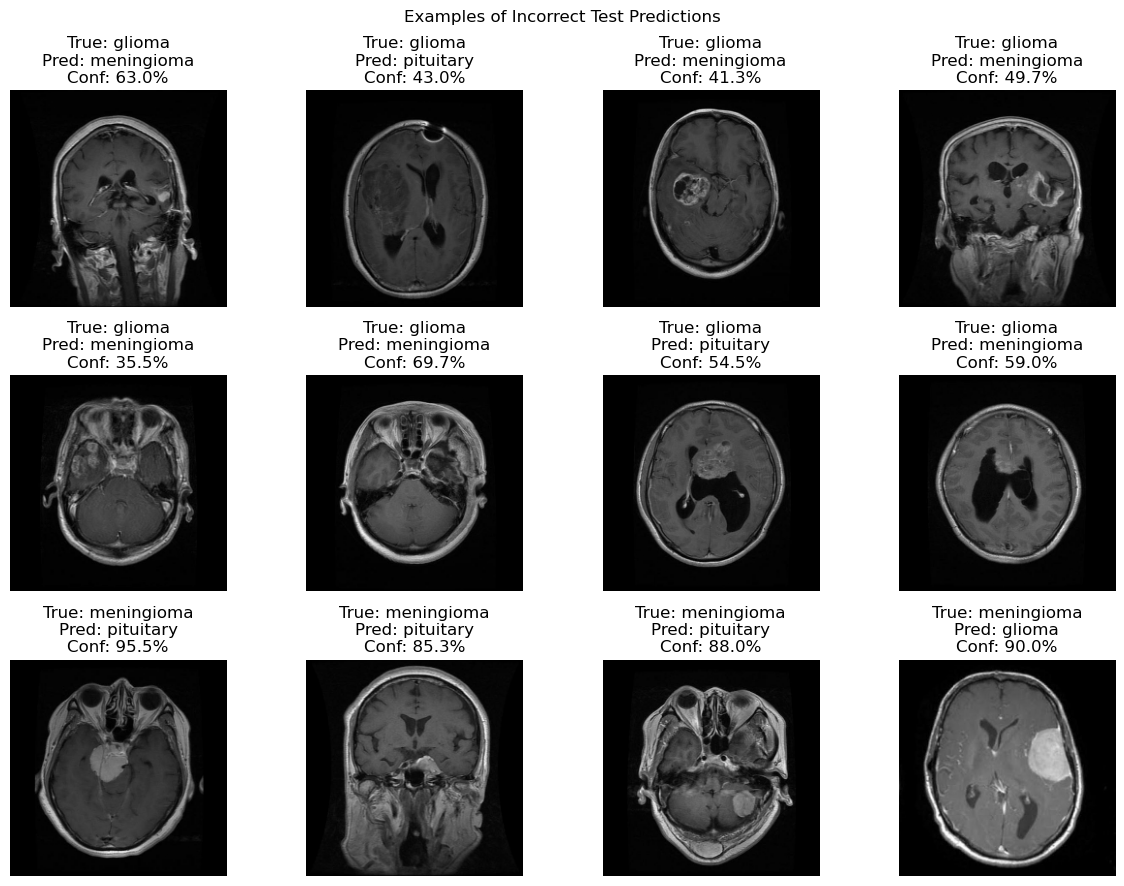

In [50]:
# ==========================================
# Chart 28: Incorrect predictions
# ==========================================

def collect_incorrect_predictions(model, dataset, max_items=12):
    records = []

    for images, labels in dataset:
        probabilities = model.predict(images, verbose=0)
        predictions = np.argmax(probabilities, axis=1)
        confidences = np.max(probabilities, axis=1)

        for i in range(len(labels)):
            true_index = int(labels[i])
            predicted_index = int(predictions[i])

            if true_index != predicted_index:
                records.append({
                    "image": images[i].numpy(),
                    "true_class": class_names[true_index],
                    "predicted_class": class_names[predicted_index],
                    "confidence": float(confidences[i])
                })

                if len(records) >= max_items:
                    return records

    return records

incorrect_examples = collect_incorrect_predictions(
    final_model,
    test_ds,
    max_items=12
)

if incorrect_examples:
    plt.figure(figsize=(12, 9))

    for i, item in enumerate(incorrect_examples):
        plt.subplot(3, 4, i + 1)
        plt.imshow(item["image"])
        plt.title(
            f"True: {item['true_class']}\n"
            f"Pred: {item['predicted_class']}\n"
            f"Conf: {item['confidence']:.1%}"
        )
        plt.axis("off")

    plt.suptitle("Examples of Incorrect Test Predictions")
    plt.tight_layout()
    plt.show()
else:
    print("No incorrect predictions were found in the displayed test samples.")

# 25. Hyperparameter Experiment

The submission template asks for cross-validation and hyperparameter tuning.

For deep CNNs, traditional k-fold cross-validation is computationally expensive because every fold requires retraining a large image model. Instead, this notebook performs a **small controlled hyperparameter experiment** using the existing validation set.

We compare two learning rates for a lightweight custom CNN.

This is intentionally small so the project remains practical on a student laptop.

> The validation set is used for tuning. The test set remains reserved for final evaluation.

In [51]:
# ==========================================
# Small hyperparameter experiment
# ==========================================

def build_small_cnn(learning_rate):
    """Build a lightweight CNN for a controlled LR experiment."""

    model = keras.Sequential([
        layers.Input(shape=(*IMG_SIZE, 3)),
        data_augmentation,

        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),

        layers.Dense(64, activation="relu"),
        layers.Dropout(0.40),

        layers.Dense(len(class_names), activation="softmax")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

# Two learning rates are compared.
learning_rates = [1e-3, 1e-4]
tuning_results = []

for lr in learning_rates:
    print(f"\nTraining lightweight CNN with learning rate = {lr}")

    experiment_model = build_small_cnn(lr)

    history = experiment_model.fit(
        train_ds,
        validation_data=valid_ds,
        epochs=3,
        class_weight=class_weights,
        verbose=1
    )

    best_val_accuracy = max(history.history["val_accuracy"])

    tuning_results.append({
        "Learning Rate": lr,
        "Best Validation Accuracy": best_val_accuracy
    })

tuning_df = pd.DataFrame(tuning_results)

print("\nHyperparameter experiment results:")
display(tuning_df)


Training lightweight CNN with learning rate = 0.001
Epoch 1/3
53/53 ━━━━━━━━━━━━━━━━━━━━ 35s 614ms/step - accuracy: 0.2619 - loss: 1.3534 - val_accuracy: 0.4562 - val_loss: 1.2852
Epoch 2/3
53/53 ━━━━━━━━━━━━━━━━━━━━ 34s 650ms/step - accuracy: 0.4796 - loss: 1.2153 - val_accuracy: 0.5060 - val_loss: 1.0458
Epoch 3/3
53/53 ━━━━━━━━━━━━━━━━━━━━ 34s 652ms/step - accuracy: 0.5280 - loss: 1.1119 - val_accuracy: 0.5060 - val_loss: 1.0104

Training lightweight CNN with learning rate = 0.0001
Epoch 1/3
53/53 ━━━━━━━━━━━━━━━━━━━━ 424s 8s/step - accuracy: 0.2218 - loss: 1.3764 - val_accuracy: 0.1972 - val_loss: 1.3802
Epoch 2/3
53/53 ━━━━━━━━━━━━━━━━━━━━ 30s 567ms/step - accuracy: 0.2000 - loss: 1.3666 - val_accuracy: 0.1972 - val_loss: 1.3767
Epoch 3/3
53/53 ━━━━━━━━━━━━━━━━━━━━ 32s 603ms/step - accuracy: 0.2142 - loss: 1.3558 - val_accuracy: 0.1972 - val_loss: 1.3719

Hyperparameter experiment results:


,Learning Rate,Best Validation Accuracy
0,0.0010,0.505976
1,0.0001,0.197211


## Chart 29 — Hyperparameter Experiment

This chart shows the validation performance obtained with each tested learning rate.

The best learning rate is the one with the strongest validation performance in this controlled experiment.

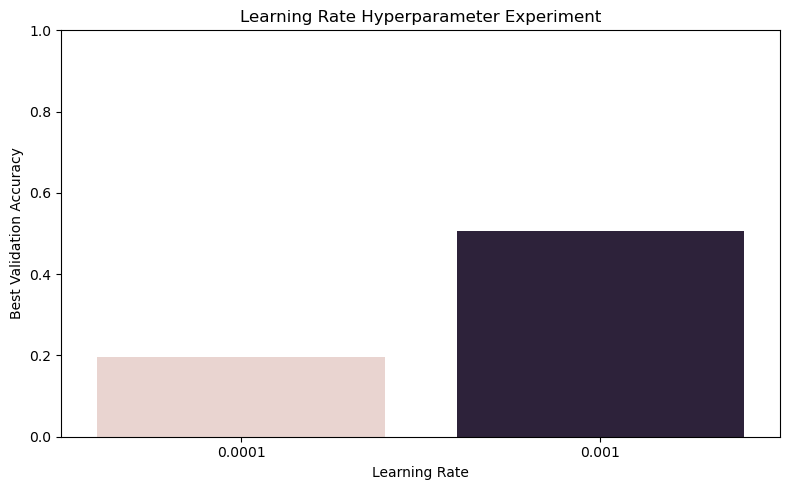

Best tested learning rate: 0.001 with validation accuracy of 0.5060


In [52]:
# ==========================================
# Chart 29: Hyperparameter tuning results
# ==========================================

plt.figure(figsize=(8, 5))
sns.barplot(
    data=tuning_df,
    x="Learning Rate",
    y="Best Validation Accuracy",
    hue="Learning Rate",
    legend=False
)
plt.title("Learning Rate Hyperparameter Experiment")
plt.xlabel("Learning Rate")
plt.ylabel("Best Validation Accuracy")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

best_lr_row = tuning_df.loc[
    tuning_df["Best Validation Accuracy"].idxmax()
]

print(
    f"Best tested learning rate: {best_lr_row['Learning Rate']} "
    f"with validation accuracy of "
    f"{best_lr_row['Best Validation Accuracy']:.4f}"
)

### Hyperparameter / Cross-Validation Note

For this image project, full k-fold cross-validation is intentionally not used in the main training pipeline because it would multiply deep-learning training time substantially.

The notebook therefore documents a practical validation-based hyperparameter experiment. If the academic evaluator explicitly requires k-fold cross-validation, it can be added as a separate experiment on a smaller subset or with a lightweight feature-based model.

# 26. Save the Final Model

The final model is saved in the modern `.keras` format.

We also save the class names separately so the Streamlit application knows the exact output order.

In [53]:
# ==========================================
# Save final model and class names
# ==========================================

FINAL_MODEL_PATH = MODEL_DIR / "brain_tumor_classifier.keras"
CLASS_NAMES_PATH = OUTPUT_DIR / "class_names.json"

# Save the trained model architecture and weights.
final_model.save(FINAL_MODEL_PATH)

# Save class names in the exact order used by the model.
with open(CLASS_NAMES_PATH, "w", encoding="utf-8") as file:
    json.dump(class_names, file, indent=4)

print("Final model saved to:")
print(FINAL_MODEL_PATH.resolve())

print("\nClass names saved to:")
print(CLASS_NAMES_PATH.resolve())

Final model saved to:
C:\Users\Dell\Downloads\Brain_Tumor_MRI_Classification\Brain_Tumor_MRI_Classification\outputs\models\brain_tumor_classifier.keras

Class names saved to:
C:\Users\Dell\Downloads\Brain_Tumor_MRI_Classification\Brain_Tumor_MRI_Classification\outputs\class_names.json


# 27. Load the Saved Model

A deployment-ready project should verify that the saved model can be loaded successfully.

This sanity check helps catch file-path or serialization problems before deployment.

In [54]:
# ==========================================
# Load saved model and class mapping
# ==========================================

loaded_model = keras.models.load_model(FINAL_MODEL_PATH)

with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as file:
    loaded_class_names = json.load(file)

print("Saved model loaded successfully.")
print("Loaded classes:", loaded_class_names)

Saved model loaded successfully.
Loaded classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']


# 28. Unseen Image Prediction Sanity Check

We now create a reusable function that accepts a single image and returns:

- Predicted class.
- Confidence score.
- All class probabilities.

This is the same basic logic that will later be used by Streamlit.

In [55]:
# ==========================================
# Single-image prediction function
# ==========================================

def predict_single_image(model, image_path, class_names):
    """Predict the class of one unseen MRI image."""

    # Open the image and force RGB format.
    image = Image.open(image_path).convert("RGB")

    # Resize to the model input size.
    image = image.resize(IMG_SIZE)

    # Convert the image into a NumPy array.
    image_array = np.array(image, dtype=np.float32)

    # Normalize pixel values from [0, 255] to [0, 1].
    image_array = image_array / 255.0

    # Add batch dimension: (224, 224, 3) -> (1, 224, 224, 3)
    image_array = np.expand_dims(image_array, axis=0)

    # Generate class probabilities.
    probabilities = model.predict(
        image_array,
        verbose=0
    )[0]

    predicted_index = int(np.argmax(probabilities))

    return {
        "predicted_class": class_names[predicted_index],
        "confidence": float(probabilities[predicted_index]),
        "probabilities": probabilities
    }

# Pick the first test image as an unseen-image sanity check.
sample_test_path = test_meta.iloc[0]["path"]

prediction_result = predict_single_image(
    loaded_model,
    sample_test_path,
    loaded_class_names
)

print("Sample image:", sample_test_path)
print("Predicted class:", prediction_result["predicted_class"])
print("Confidence:", f"{prediction_result['confidence']:.2%}")

print("\nAll class probabilities:")
for name, probability in zip(
    loaded_class_names,
    prediction_result["probabilities"]
):
    print(f"{name}: {probability:.2%}")

Sample image: dataset (2)\Tumour\test\glioma\Tr-gl_0016_jpg.rf.99746694ea97fe0b73108832b462d48e.jpg
Predicted class: meningioma
Confidence: 51.94%

All class probabilities:
glioma: 37.87%
meningioma: 51.94%
no_tumor: 0.07%
pituitary: 10.12%


# 29. Final Evaluation Summary

This section prints the final selected model's metrics in a compact form.

Remember that these numbers describe performance on the supplied dataset. They do not establish clinical usefulness.

In [56]:
# ==========================================
# Final evaluation summary
# ==========================================

final_accuracy = accuracy_score(final_y_true, final_y_pred)
final_precision = precision_score(
    final_y_true,
    final_y_pred,
    average="macro",
    zero_division=0
)
final_recall = recall_score(
    final_y_true,
    final_y_pred,
    average="macro",
    zero_division=0
)
final_f1 = f1_score(
    final_y_true,
    final_y_pred,
    average="macro",
    zero_division=0
)

final_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],
    "Score": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1
    ]
})

display(
    final_summary.style.format({
        "Score": "{:.4f}"
    })
)

,Metric,Score
0,Accuracy,0.8577
1,Macro Precision,0.8625
2,Macro Recall,0.8565
3,Macro F1,0.8541


# 30. Streamlit Deployment

The following code creates a simple Streamlit application.

### Application flow

**Upload MRI → Display image → Preprocess → Predict → Show class + confidence → Show class probabilities**

The application includes an educational/research disclaimer and should not be presented as a clinical diagnostic tool.

In [57]:
# ==========================================
# Streamlit app code
# ==========================================
#
# Copy this entire cell into a file named:
# app.py
#
# Run from the project root using:
# streamlit run app.py
#

streamlit_code = r'''
import json
from pathlib import Path

import numpy as np
import streamlit as st
from PIL import Image
from tensorflow.keras.models import load_model


# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

MODEL_PATH = Path("outputs/models/brain_tumor_classifier.keras")
CLASS_NAMES_PATH = Path("outputs/class_names.json")


# ---------------------------------------------------------
# Load model only once and cache it.
# ---------------------------------------------------------

@st.cache_resource
def load_saved_model():
    return load_model(MODEL_PATH)


# ---------------------------------------------------------
# Load class names only once.
# ---------------------------------------------------------

@st.cache_data
def load_class_names():
    with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as file:
        return json.load(file)


# ---------------------------------------------------------
# Preprocess uploaded image.
# ---------------------------------------------------------

def preprocess_image(image):
    # Convert to RGB so that the input always has 3 channels.
    image = image.convert("RGB")

    # Resize to the same dimensions used during training.
    image = image.resize((224, 224))

    # Convert to NumPy and normalize to [0, 1].
    image_array = np.asarray(
        image,
        dtype=np.float32
    ) / 255.0

    # Add batch dimension.
    return np.expand_dims(image_array, axis=0)


# ---------------------------------------------------------
# Streamlit page configuration.
# ---------------------------------------------------------

st.set_page_config(
    page_title="Brain Tumor MRI Classifier",
    page_icon="🧠",
    layout="centered"
)

st.title("🧠 Brain Tumor MRI Image Classification")

st.write(
    "Upload an MRI image to obtain an educational model prediction."
)

st.warning(
    "This application is for educational/research purposes only. "
    "The prediction is not a medical diagnosis and should not "
    "replace evaluation by a qualified healthcare professional."
)


# ---------------------------------------------------------
# Check required model files.
# ---------------------------------------------------------

if not MODEL_PATH.exists():
    st.error(
        f"Model file not found: {MODEL_PATH}"
    )
    st.stop()

if not CLASS_NAMES_PATH.exists():
    st.error(
        f"Class mapping file not found: {CLASS_NAMES_PATH}"
    )
    st.stop()


# ---------------------------------------------------------
# Load saved assets.
# ---------------------------------------------------------

model = load_saved_model()
class_names = load_class_names()


# ---------------------------------------------------------
# Upload image.
# ---------------------------------------------------------

uploaded_file = st.file_uploader(
    "Upload a brain MRI image",
    type=["jpg", "jpeg", "png", "bmp", "webp"]
)


if uploaded_file is not None:

    # Open uploaded image.
    image = Image.open(uploaded_file).convert("RGB")

    # Display original image.
    st.image(
        image,
        caption="Uploaded MRI Image",
        use_container_width=True
    )

    if st.button("Predict Tumor Class"):

        # Preprocess the image.
        input_image = preprocess_image(image)

        # Generate probabilities.
        probabilities = model.predict(
            input_image,
            verbose=0
        )[0]

        # Find the class with the highest probability.
        predicted_index = int(
            np.argmax(probabilities)
        )

        predicted_class = class_names[predicted_index]

        confidence = float(
            probabilities[predicted_index]
        )

        # Display prediction.
        st.subheader("Prediction")

        st.write(
            f"**Predicted class:** {predicted_class}"
        )

        st.write(
            f"**Model confidence:** {confidence:.2%}"
        )

        # Display probability for every class.
        st.subheader("Class Scores")

        probability_data = {
            class_names[i]: float(probabilities[i])
            for i in range(len(class_names))
        }

        st.bar_chart(probability_data)
'''

print(streamlit_code)


import json
from pathlib import Path

import numpy as np
import streamlit as st
from PIL import Image
from tensorflow.keras.models import load_model


# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

MODEL_PATH = Path("outputs/models/brain_tumor_classifier.keras")
CLASS_NAMES_PATH = Path("outputs/class_names.json")


# ---------------------------------------------------------
# Load model only once and cache it.
# ---------------------------------------------------------

@st.cache_resource
def load_saved_model():
    return load_model(MODEL_PATH)


# ---------------------------------------------------------
# Load class names only once.
# ---------------------------------------------------------

@st.cache_data
def load_class_names():
    with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as file:
        return json.load(file)


# ---------------------------------------------------------
# Prepro

# 31. Streamlit Setup Commands

After running the notebook and creating the saved model, create a new file named:

```text
app.py
```

Paste the Streamlit code from the previous cell into that file.

Then, from the project root terminal:

```bash
pip install streamlit
streamlit run app.py
```

The application should open in your browser.

### Expected project structure

```text
Brain_Tumor_MRI_Classification/
│
├── DATASET_DIR/
│   └── Tumour/
│
├── outputs/
│   ├── models/
│   │   └── brain_tumor_classifier.keras
│   └── class_names.json
│
├── notebook/
│   └── brain_tumor_mri_classification.ipynb
│
└── app.py
```

# 32. Key Findings

The following points should be discussed after executing the notebook:

1. **Dataset distribution:**  
   Explain whether the four classes are balanced or imbalanced based on Chart 1.

2. **Image characteristics:**  
   Discuss the observed image dimensions, aspect ratios and brightness distributions.

3. **Preprocessing:**  
   Explain why images were resized to 224 × 224 and normalized.

4. **Data augmentation:**  
   Explain how augmentation reduces overfitting and improves training diversity.

5. **Custom CNN:**  
   Report its accuracy, macro precision, macro recall and macro F1.

6. **Transfer learning:**  
   Report the corresponding MobileNetV2 results.

7. **Fine-tuning:**  
   Explain whether fine-tuning improved validation/test performance.

8. **Model comparison:**  
   Select the model using multiple metrics, with particular attention to macro F1.

9. **Error analysis:**  
   Discuss the classes that are commonly confused.

10. **Deployment:**  
    Explain how the saved model is used by the Streamlit application.

# 33. Limitations

This project has several important limitations:

- The model learns only from the supplied dataset.
- Dataset bias may affect generalization.
- External clinical validation has not been performed.
- Image quality and acquisition settings may vary in real-world MRI systems.
- Accuracy and confidence scores do not establish medical reliability.
- The Streamlit application is an educational demonstration, not a clinical diagnostic system.
- Full k-fold deep-learning cross-validation was not used because it is computationally expensive for this image task.

# 34. Future Work

Possible improvements include:

- Test EfficientNetB0, ResNet50 and other pretrained architectures.
- Perform systematic hyperparameter optimization.
- Add Grad-CAM for visual explainability.
- Add perceptual duplicate-image detection.
- Use external datasets for robustness testing.
- Add image-quality validation before inference.
- Investigate class-specific augmentation strategies.
- Perform proper clinical validation with expert-reviewed datasets.
- Containerize the Streamlit application for deployment.

# 35. Conclusion

This project implements a complete deep-learning workflow for multi-class brain MRI image classification.

The workflow covers:

**Dataset Understanding → EDA → Preprocessing → Augmentation → Custom CNN → Transfer Learning → Fine-Tuning → Evaluation → Hyperparameter Experiment → Model Comparison → Model Saving → Streamlit Deployment**

The custom CNN provides a baseline model trained from scratch, while MobileNetV2 provides a transfer-learning approach using pretrained visual features.

The final model should be selected using class-aware metrics such as macro precision, macro recall and macro F1 rather than accuracy alone.

The saved model can be integrated into Streamlit for an interactive educational demonstration. Any prediction must be interpreted as a model output and not as a clinical diagnosis.

# 36. Final Project Checklist

Before submission, verify:

- [ ] Notebook runs from beginning to end without errors.
- [ ] Dataset path is correct.
- [ ] Four classes are detected correctly.
- [ ] EDA charts are generated.
- [ ] At least 15 meaningful charts are included.
- [ ] Custom CNN is trained.
- [ ] MobileNetV2 transfer-learning model is trained.
- [ ] Fine-tuning is completed.
- [ ] Accuracy, precision, recall and F1 are reported.
- [ ] Confusion matrices are included.
- [ ] Model comparison is included.
- [ ] Hyperparameter experiment is documented.
- [ ] Final model is saved.
- [ ] Class mapping is saved.
- [ ] Saved model can be loaded successfully.
- [ ] Unseen-image prediction is tested.
- [ ] `app.py` is created.
- [ ] Streamlit app runs successfully.
- [ ] Medical/research disclaimer is displayed.
- [ ] GitHub README is prepared.

# End of Notebook

**Brain Tumor MRI Image Classification — Deep Learning Project**

The notebook is designed to be executed sequentially from top to bottom.